# Timing Games on Ethereum: Who Pays for Waiting?

Analysis code for the paper. Run the cells top to bottom.

* Every query result is cached as `cache_<name>.parquet`. The released
  data live in `data/`; with them, the whole notebook runs offline, without
  database access.
* To re-pull from Xatu instead, set the environment variables `XATU_USER`
  and `XATU_PASSWORD` (ethPandaOps ClickHouse) and delete the cache files
  you want to refresh (or call `cached(..., refresh=True)`).
* Figures go to `fig/`, LaTeX tables to the working directory, and the key
  numbers quoted in the paper to `numbers.json`.

Section numbers in the headings follow the paper.

In [1]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import statsmodels.api as sm
from scipy.stats import spearmanr, mannwhitneyu

try:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats("retina")
except ImportError:
    pass

mpl.rcParams.update({
    "figure.figsize":     (3.33, 2.2),   # one column; (6.9, h) for full width
    "savefig.format":     "pdf",
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.02,
    "pdf.fonttype":       42,            # embed TrueType, not Type 3
    "ps.fonttype":        42,
    "font.family":        "serif",
    "font.serif":         ["Linux Libertine", "Times New Roman", "DejaVu Serif"],
    "font.size":          8,
    "axes.labelsize":     8,
    "axes.titlesize":     8,
    "xtick.labelsize":    7,
    "ytick.labelsize":    7,
    "legend.fontsize":    7,
    "axes.linewidth":     0.6,
    "lines.linewidth":    1.0,
    "grid.linewidth":     0.4,
})
pd.set_option("display.max_columns", None)
os.makedirs("fig", exist_ok=True)

In [2]:
# ---- protocol ----
GENESIS         = 1606824023     # beacon chain genesis (unix seconds)
SLOT_SEC        = 12
SLOTS_PER_MONTH = 216_000        # 30 days x 7,200 slots
FUSAKA_SLOT     = 13_164_544     # 2025-12-03
TRANSITION_END  = 14_400_000     # ~2026-05, end of the post-Fusaka transition

# ---- study window (inclusive months) ----
START = (2024, 10)
END   = (2026, 10)

# ---- sentry selection (Section 3.2) ----
MAX_MS                = 12_000   # observations at or past 12 s fall into a later slot
MIN_COVERAGE          = 0.5      # a sentry-month counts if it sees >= 50% of slots
MIN_SENTRY_MONTHS     = 8        # a sentry needs >= 8 such months
MIN_SENTRIES_PER_SLOT = 10       # a slot needs >= 10 retained sentries

# ---- operator classification (Section 3.3) ----
LATE_MS     = 3200               # late block: arrives >= 3.2 s into the slot
DELAY       = 0.30               # delaying operator-month: late share >= 30%
MIN_BLOCKS  = 100                # operator-month needs >= 100 blocks
MAX_MED_MS  = 4000               # ... and a median of at most 4 s
MIN_RUN     = 12                 # operator needs >= 12 consecutive qualifying months
HEAD = TAIL = 2                  # first / last months compared

# ---- costs (Section 5) ----
HEAD_BASE_MS = (1500, 2000)      # baseline head-vote rate
BURDEN_LATE  = (3200, 4000)      # late-block window for the attester burden
BURDEN_NORM  = (1500, 2000)      # on-time window for the attester burden

In [28]:
CH = {"max_bytes_before_external_group_by": 4_000_000_000}   # query settings
DATA_DIR = "data"                                             # released data
OFFLINE = "XATU_PASSWORD" not in os.environ

if OFFLINE:
    client = remote = None
    print(f"Offline mode: reading all inputs from {DATA_DIR}/")
else:
    from clickhouse_connect import get_client
    client = get_client(host="localhost", port=8123)          # local Xatu mirror
    remote = get_client(
        host="clickhouse-refined.analytics.production.platform.ethpandaops.io",
        port=443, secure=True,
        username=os.environ["XATU_USER"],
        password=os.environ["XATU_PASSWORD"],
        database="mainnet",
    )

In [4]:
def month_list(start, end):
    y, m = start
    out = []
    while (y, m) <= end:
        out.append((y, m))
        y, m = (y + 1, 1) if m == 12 else (y, m + 1)
    return out


MONTHS = month_list(START, END)


def bounds(y, m):
    """First day of the month and of the next month, as strings."""
    lo = f"{y}-{m:02d}-01"
    hi = f"{y + 1}-01-01" if m == 12 else f"{y}-{m + 1:02d}-01"
    return lo, hi


def pull(fn, months=MONTHS):
    """Run fn(lo, hi) for every month and concatenate the results."""
    parts = []
    for y, m in months:
        lo, hi = bounds(y, m)
        try:
            p = fn(lo, hi)
            if p is not None and len(p):
                parts.append(p)
        except Exception as e:
            print(lo, "skip:", str(e).split("DB::Exception:")[-1][:120])
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()


CACHE_USED = []   # names of every cache this run reads, for export_release()


def cached(name, fn, refresh=False):
    """Load cache_<name>.parquet from data/ or the working directory if present;
    otherwise run fn() (a database query) and save the result."""
    CACHE_USED.append(name)
    for d_ in (DATA_DIR, "."):
        path = os.path.join(d_, f"cache_{name}.parquet")
        if os.path.exists(path) and not refresh:
            return pd.read_parquet(path)
    if OFFLINE:
        raise FileNotFoundError(
            f"cache_{name}.parquet not found in {DATA_DIR}/ and no database access "
            "(set XATU_USER and XATU_PASSWORD to re-pull it)")
    df = fn()
    df.to_parquet(f"cache_{name}.parquet")
    return df


def slot_time(slot):
    """Slot start time for a Series (or array) of slots."""
    return pd.to_datetime(GENESIS + pd.Series(slot).astype("int64") * SLOT_SEC, unit="s")


def ts_to_slot(ts):
    return int((pd.Timestamp(ts).timestamp() - GENESIS) // SLOT_SEC)


SLOT_START = ts_to_slot(bounds(*START)[0])
SLOT_END   = ts_to_slot(bounds(*END)[1])     # exclusive


def in_window(df):
    return df[(df.slot >= SLOT_START) & (df.slot < SLOT_END)]


def peek(table, where=None, n=3, db="mainnet"):
    """Print a remote table's schema and a few sample rows."""
    schema = remote.query_df(f"DESCRIBE {db}.{table}")
    print(f"=== {table} ===")
    for _, r_ in schema.iterrows():
        print(f"  {r_['name']:<30} {r_['type']}")
    cond = f"WHERE {where}" if where else ""
    try:
        df = remote.query_df(f"SELECT * FROM {db}.{table} {cond} LIMIT {n}")
        for i in range(len(df)):
            print(f"\n--- row {i} ---")
            for c in df.columns:
                print(f"  {c:<30} {str(df.iloc[i][c]).replace(chr(10), ' ')[:70]}")
    except Exception as e:
        print("\nsample failed:", str(e).split("DB::Exception:")[-1][:140])


def month_ticks(ax, months, step=3):
    ax.set_xticks(range(0, len(months), step))
    ax.set_xticklabels([str(months[i]) for i in range(0, len(months), step)],
                       rotation=45, ha="right")


def tex_escape(s):
    return str(s).replace("_", r"\_").replace("%", r"\%")


NUM = {}   # numbers quoted in the paper, written to numbers.json at the end

## 3.1 Data

* `sentry`: observations per sentry and month (for sentry selection)
* `arr`: per-slot median propagation time across retained sentries
* `prop`: proposer index of every observed block
* `nodes`: validator index -> operator label
* `mev`: MEV-Boost payment and block status per slot

In [5]:
sentry = cached("sentry", lambda: pull(lambda lo, hi: client.query_df(f"""
    SELECT toYYYYMM(slot_start_date_time) AS ym, meta_client_name,
           count() AS n_obs, uniq(slot) AS n_slots
    FROM beacon_api_eth_v1_events_block
    WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
      AND propagation_slot_start_diff < {MAX_MS}
    GROUP BY ym, meta_client_name
""", settings=CH)))
sentry["ym"] = pd.to_datetime(sentry.ym.astype(str), format="%Y%m").dt.to_period("M")

good = (sentry.assign(cov=sentry.n_slots / SLOTS_PER_MONTH)
              .query("cov >= @MIN_COVERAGE")
              .groupby("meta_client_name").size())
SENTRIES = sorted(good[good >= MIN_SENTRY_MONTHS].index)
SENTRY_SQL = ",".join(f"'{s_}'" for s_ in SENTRIES)

NUM["obs_total"]      = int(sentry.n_obs.sum())
NUM["sentries_total"] = int(sentry.meta_client_name.nunique())
NUM["sentries_kept"]  = len(SENTRIES)
NUM["obs_kept"]       = int(sentry[sentry.meta_client_name.isin(SENTRIES)].n_obs.sum())
print(f"{NUM['obs_total']:,} observations from {NUM['sentries_total']} sentries; "
      f"retained {NUM['sentries_kept']} sentries ({NUM['obs_kept']:,} observations)")

541,048,823 observations from 3225 sentries; retained 108 sentries (277,581,831 observations)


In [6]:
sentry_med = cached("sentry_median", lambda: pull(lambda lo, hi: client.query_df(f"""
    SELECT meta_client_name,
           quantile(0.5)(propagation_slot_start_diff) AS med, count() AS n
    FROM beacon_api_eth_v1_events_block
    WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
      AND propagation_slot_start_diff < {MAX_MS}
      AND meta_client_name IN ({SENTRY_SQL})
    GROUP BY meta_client_name
""", settings=CH)))
per_sentry = (sentry_med.groupby("meta_client_name")
                        .apply(lambda x: np.average(x.med, weights=x.n))
                        .sort_values())
NUM["sentry_median_min"] = float(per_sentry.min())
NUM["sentry_median_max"] = float(per_sentry.max())
NUM["sentry_median_std"] = float(per_sentry.std())
print(per_sentry.describe().round(0))

count     108.0
mean     2144.0
std       228.0
min      1718.0
25%      1967.0
50%      2108.0
75%      2295.0
max      2769.0
dtype: float64


In [7]:
arr = cached("arr", lambda: pull(lambda lo, hi: client.query_df(f"""
    SELECT slot,
           toUInt32(quantile(0.5)(propagation_slot_start_diff)) AS t_ms,
           uniq(meta_client_name) AS n_sentry
    FROM beacon_api_eth_v1_events_block
    WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
      AND propagation_slot_start_diff < {MAX_MS}
      AND meta_client_name IN ({SENTRY_SQL})
    GROUP BY slot
""", settings=CH)))

prop = cached("prop", lambda: pull(lambda lo, hi: client.query_df(f"""
    SELECT slot, any(proposer_index) AS pidx
    FROM beacon_api_eth_v2_beacon_block
    WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
    GROUP BY slot
""", settings=CH)))

nodes = cached("nodes", lambda: remote.query_df("""
    SELECT validator_index, source
    FROM mainnet.dim_node
    WHERE validator_index BETWEEN 0 AND 4000000
"""))

mev = cached("mev", lambda: pull(lambda lo, hi: remote.query_df(f"""
    SELECT slot, toFloat64(any(value)) / 1e18 AS mev_eth, any(status) AS status
    FROM mainnet.fct_block_mev
    WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
      AND slot BETWEEN 0 AND 99999999
    GROUP BY slot
""")))

In [8]:
arr = in_window(arr.drop_duplicates("slot"))
arr = arr[arr.n_sentry >= MIN_SENTRIES_PER_SLOT].copy()
arr["ts"] = slot_time(arr.slot).values
arr["ym"] = arr.ts.dt.to_period("M")

prop = in_window(prop.drop_duplicates("slot"))
mev  = in_window(mev.drop_duplicates("slot"))

# Coinbase validators created through batch deposits are the same product
nodes["source"] = nodes.source.replace({"coinbase_batch_deposit": "coinbase"})
SOURCE_OF = nodes.set_index("validator_index").source

# d: one row per observed block with its operator
d = (arr[["slot", "t_ms", "ts", "ym"]]
     .merge(prop, on="slot")
     .merge(nodes, left_on="pidx", right_on="validator_index", how="left"))
d["source"] = d.source.fillna("unlabeled")

# z: MEV-Boost blocks only
z = d.merge(mev, on="slot", how="inner")
z["orphaned"] = (z.status == "orphaned").astype(int)

# share of each operator's blocks that went through MEV-Boost
mevboost_rate = (d.merge(mev[["slot"]], on="slot", how="left", indicator=True)
                  .assign(matched=lambda x: x._merge == "both")
                  .groupby("source").matched.mean())

NUM["slots_used"]  = len(arr)
NUM["slots_total"] = SLOT_END - SLOT_START
print(f"{len(d):,} blocks | labeled {(d.source != 'unlabeled').mean():.1%} | "
      f"MEV-Boost {len(z) / len(d):.1%} | "
      f"slots used {NUM['slots_used'] / NUM['slots_total']:.1%} of window")

5,434,741 blocks | labeled 100.0% | MEV-Boost 91.6% | slots used 99.2% of window


In [9]:
cover = (d.groupby("ym").agg(slots=("slot", "size"), ops=("source", "nunique"))
           .assign(expected=lambda x: x.index.map(lambda p: p.days_in_month * 7200)))
cover["coverage"] = (cover.slots / cover.expected).round(3)
print(cover.to_string())

          slots   ops  expected  coverage
ym                                       
2024-10  203599   653    223200     0.912
2024-11  212593   770    216000     0.984
2024-12  222074   804    223200     0.995
2025-01  222340   807    223200     0.996
2025-02  200641   826    201600     0.995
2025-03  222379   858    223200     0.996
2025-04  215260   854    216000     0.997
2025-05  221116   870    223200     0.991
2025-06  214710   861    216000     0.994
2025-07  222133   887    223200     0.995
2025-08  222395   883    223200     0.996
2025-09  214990   872    216000     0.995
2025-10  221936   915    223200     0.994
2025-11  214551   942    216000     0.993
2025-12  221641  1001    223200     0.993
2026-01  222526   995    223200     0.997
2026-02  200924   967    201600     0.997
2026-03  222250   987    223200     0.996
2026-04  215518   997    216000     0.998
2026-05  222617  1029    223200     0.997
2026-06  215349  1063    216000     0.997
2026-07  222606  1040    223200   

In [10]:
fleet = (sentry.groupby("ym").meta_client_name.nunique().rename("n_all").to_frame()
         .join(sentry[sentry.meta_client_name.isin(SENTRIES)]
               .groupby("ym").meta_client_name.nunique().rename("n_kept"))
         .join(arr.groupby("ym").t_ms.median().rename("med_ms")))
print(fleet.to_string())

         n_all  n_kept  med_ms
ym                            
2024-10     53      15  2187.0
2024-11     40      16  2226.0
2024-12     51      17  2246.0
2025-01     92      18  2233.0
2025-02    163      27  2250.0
2025-03    181      30  2257.0
2025-04    301      36  2231.0
2025-05    293      41  2179.0
2025-06    268      37  2131.0
2025-07    312      44  2182.0
2025-08    322      52  2190.0
2025-09    292      59  2208.0
2025-10    208      59  2250.0
2025-11    317      66  2263.0
2025-12    394      82  2125.0
2026-01    269      85  2127.0
2026-02    303      87  2072.0
2026-03    220      85  2031.0
2026-04    224      82  1947.0
2026-05    274      81  1944.0
2026-06    262      81  1962.0
2026-07    260      78  1969.0
2026-08    226      75  1979.0
2026-09    229      73  1974.0
2026-10    271      69  1903.0


## 4. Who Delays? The Spread of Timing Games

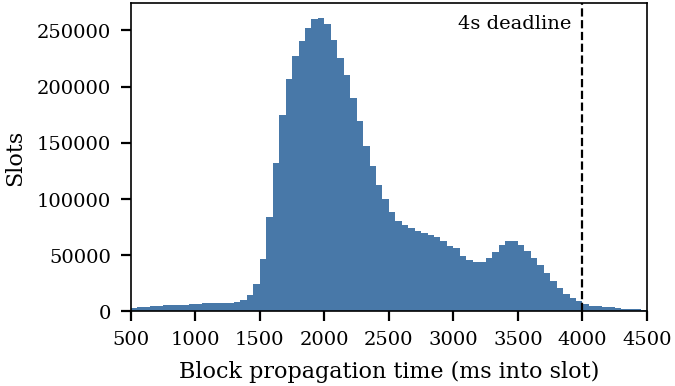

In [11]:
bins50 = np.arange(0, 5001, 50)
NUM["share_above_4500ms"] = float((arr.t_ms >= 4500).mean())

fig, ax = plt.subplots(figsize=(3.33, 2.0))
ax.hist(arr.t_ms[arr.t_ms < 5000], bins=bins50, color="#4878A8", edgecolor="none")
ax.axvline(4000, color="k", ls="--", lw=0.8)
ax.annotate("4s deadline", xy=(4000, 1), xytext=(-4, -4),
            xycoords=("data", "axes fraction"), textcoords="offset points",
            va="top", ha="right", fontsize=7)
ax.set_xlabel("Block propagation time (ms into slot)")
ax.set_ylabel("Slots")
ax.set_xlim(500, 4500)
fig.savefig("fig/arrival_hist.pdf")

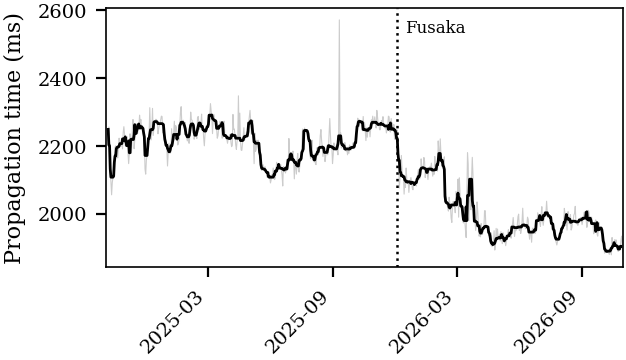

In [12]:
daily = arr.groupby(arr.ts.dt.date).t_ms.median()
fusaka_day = pd.Timestamp("2025-12-03").date()

fig, ax = plt.subplots(figsize=(3.33, 2.0))
ax.plot(daily.index, daily.values, lw=.4, color="#CCCCCC")
ax.plot(daily.index, daily.rolling(7, center=True).median(), lw=1.0, color="k")
ax.axvline(fusaka_day, c="k", ls=":", lw=.9)
ax.annotate("Fusaka", xy=(fusaka_day, 1), xytext=(3, -4),
            xycoords=("data", "axes fraction"), textcoords="offset points",
            va="top", ha="left", fontsize=6)
ax.set_ylabel("Propagation time (ms)")
ax.margins(x=0)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
fig.savefig("fig/prop_time_change.pdf")

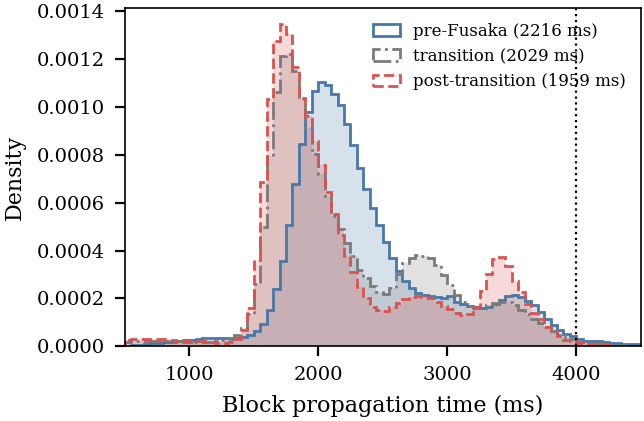

In [13]:
edges = [arr.slot.min(), FUSAKA_SLOT, TRANSITION_END, arr.slot.max() + 1]
periods = ["pre-Fusaka", "transition", "post-transition"]
styles = [("#4878A8", "-"), ("#7A7A7A", "-."), ("#D9534F", "--")]

fig, ax = plt.subplots(figsize=(3.33, 2.2))
for (c, ls), nm, (a, b) in zip(styles, periods, zip(edges[:-1], edges[1:])):
    s_ = arr.t_ms[(arr.slot >= a) & (arr.slot < b)]
    ax.hist(s_, bins=bins50, density=True, histtype="stepfilled", alpha=.22, color=c)
    ax.hist(s_, bins=bins50, density=True, histtype="step", color=c, lw=1.0, ls=ls,
            label=f"{nm} ({s_.median():.0f} ms)")
ax.axvline(4000, c="k", ls=":", lw=.8)
ax.set_xlabel("Block propagation time (ms)")
ax.set_ylabel("Density")
ax.set_xlim(500, 4500)
ax.set_xticks([1000, 2000, 3000, 4000])
ax.legend(fontsize=6, frameon=False, handlelength=1.6)
fig.savefig("fig/arrival_hist_divided.pdf")

In [14]:
block_meta = cached("block_meta", lambda: pull(lambda lo, hi: remote.query_df(f"""
    SELECT slot, block_total_bytes AS bytes,
           execution_payload_gas_used AS gas,
           toUInt16(execution_payload_blob_gas_used / 131072) AS n_blob
    FROM mainnet.fct_block
    WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
      AND slot BETWEEN 0 AND 99999999
""")))

bm = arr[["slot", "t_ms", "ym"]].merge(block_meta, on="slot")
bm["size_q"] = pd.qcut(bm.bytes, 5, labels=False, duplicates="drop")
pre, post = bm[bm.ym <= pd.Period("2025-11")], bm[bm.ym >= pd.Period("2026-04")]

size_rng = bm.groupby("size_q").bytes.agg(["min", "max"]) / 1024
by_size = pd.DataFrame({
    "size (KB)": size_rng.apply(lambda r_: f"{r_['min']:.0f}-{r_['max']:.0f}", axis=1),
    "pre-Fusaka": pre.groupby("size_q").t_ms.median(),
    "post": post.groupby("size_q").t_ms.median()})
by_size["delta"] = by_size.post - by_size["pre-Fusaka"]
print(by_size.round(0).to_string())

by_blob = (bm.assign(has_blob=bm.n_blob > 0)
             .groupby(["ym", "has_blob"]).agg(med=("t_ms", "median"), n=("t_ms", "size")))
print(by_blob.unstack().round(0).to_string())

       size (KB)  pre-Fusaka    post  delta
size_q                                     
0           2-87      2067.0  1726.0 -341.0
1         87-111      2199.0  1833.0 -366.0
2        111-139      2268.0  1875.0 -393.0
3        139-188      2331.0  1939.0 -392.0
4       188-1949      2400.0  2067.0 -333.0
             med              n        
has_blob   False   True   False   True 
ym                                     
2024-10   2084.0  2237.0  70393  133206
2024-11   2107.0  2275.0  67246  145354
2024-12   2130.0  2290.0  69696  152378
2025-01   2109.0  2276.0  63151  159189
2025-02   2161.0  2288.0  62780  137863
2025-03   2187.0  2286.0  65260  157128
2025-04   2146.0  2265.0  61985  153275
2025-05   2093.0  2213.0  64359  156757
2025-06   2052.0  2161.0  57342  157369
2025-07   2105.0  2216.0  65919  156214
2025-08   2118.0  2220.0  63107  159289
2025-09   2116.0  2227.0  39403  175588
2025-10   2129.0  2268.0  29203  192733
2025-11   2137.0  2278.0  21556  193031
2025-12   19

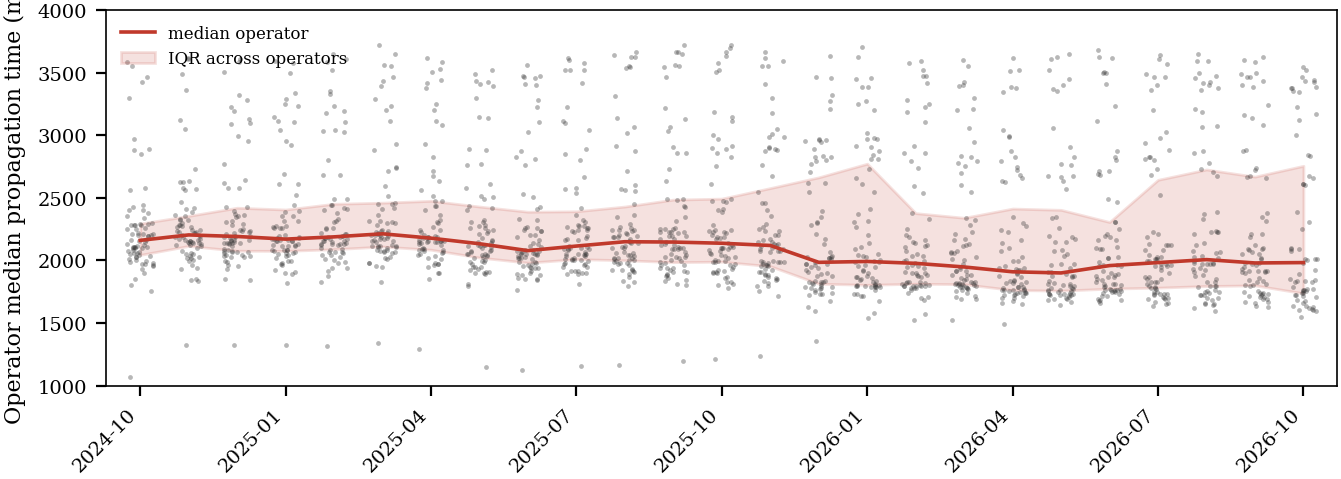

In [15]:
op_month = (d.groupby(["source", "ym"]).agg(n=("t_ms", "size"), med=("t_ms", "median"))
              .reset_index())
spread = op_month.query("n >= 500").copy()
spread_months = sorted(spread.ym.unique())
spread["i"] = spread.ym.map({m_: i for i, m_ in enumerate(spread_months)})

fig, ax = plt.subplots(figsize=(6.9, 2.6))
jitter = np.random.default_rng(0).uniform(-.28, .28, len(spread))
ax.scatter(spread.i + jitter, spread.med, s=3, alpha=.35, color="#333333",
           linewidths=0, zorder=2)
q = spread.groupby("i").med.quantile([.25, .5, .75]).unstack()
ax.plot(q.index, q[.50], color="#C0392B", lw=1.3, zorder=3, label="median operator")
ax.fill_between(q.index, q[.25], q[.75], color="#C0392B", alpha=.15, zorder=1,
                label="IQR across operators")
month_ticks(ax, spread_months)
ax.set_xlim(-.7, len(spread_months) - .3)
ax.set_ylim(1000, 4000)
ax.set_ylabel("Operator median propagation time (ms)")
ax.legend(fontsize=6, frameon=False, loc="upper left")
plt.tight_layout()
fig.savefig("fig/operator_spread.pdf")

In [16]:
def longest_run(months):
    """Longest streak of consecutive months."""
    ms = sorted(months)
    best = run = 1
    for a, b in zip(ms, ms[1:]):
        run = run + 1 if (b - a).n == 1 else 1
        best = max(best, run)
    return best


pan = (d.assign(late=d.t_ms >= LATE_MS)
        .groupby(["source", "ym"])
        .agg(n=("t_ms", "size"), med_ms=("t_ms", "median"), late=("late", "mean"))
        .reset_index())
n_before = len(pan.query("n >= @MIN_BLOCKS"))
pan = pan.query("n >= @MIN_BLOCKS and med_ms <= @MAX_MED_MS")
NUM["opmonths_dropped_over_4s"] = 1 - len(pan) / n_before

keep = [s_ for s_, g_ in pan.groupby("source") if longest_run(g_.ym) >= MIN_RUN]
pan = pan[pan.source.isin(keep) & (pan.source != "unlabeled")].copy()

PAN_MONTHS = sorted(pan.ym.unique())
pos = {m_: i for i, m_ in enumerate(PAN_MONTHS)}
by_size_order = pan.groupby("source").n.sum().sort_values(ascending=False).index
net_late = d.assign(l=d.t_ms >= LATE_MS).groupby("ym").l.mean()

NUM["operators"]        = int(pan.source.nunique())
NUM["operator_blocks"]  = float(d.source.isin(pan.source.unique()).mean())
NUM["late_share_all"]   = float((d.t_ms >= LATE_MS).mean())
print(f"{NUM['operators']} operators, {NUM['operator_blocks']:.1%} of blocks, "
      f"{NUM['late_share_all']:.1%} of blocks late, "
      f"{NUM['opmonths_dropped_over_4s']:.2%} operator-months dropped (median > 4 s)")

108 operators, 87.8% of blocks, 13.0% of blocks late, 0.14% operator-months dropped (median > 4 s)


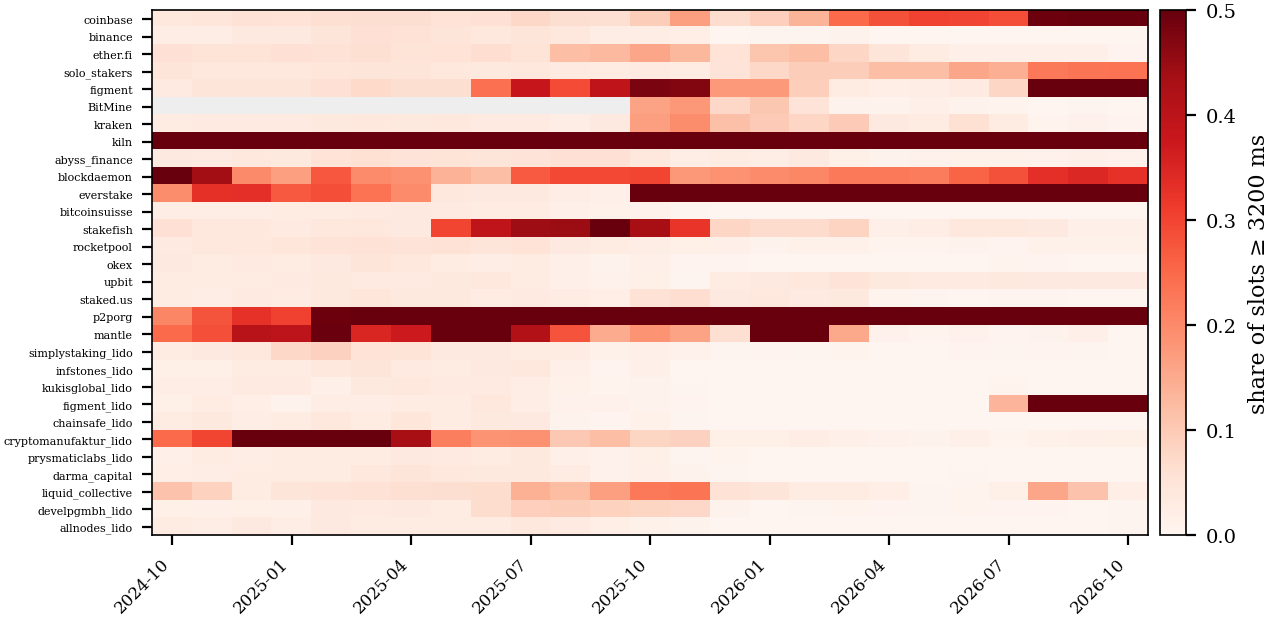

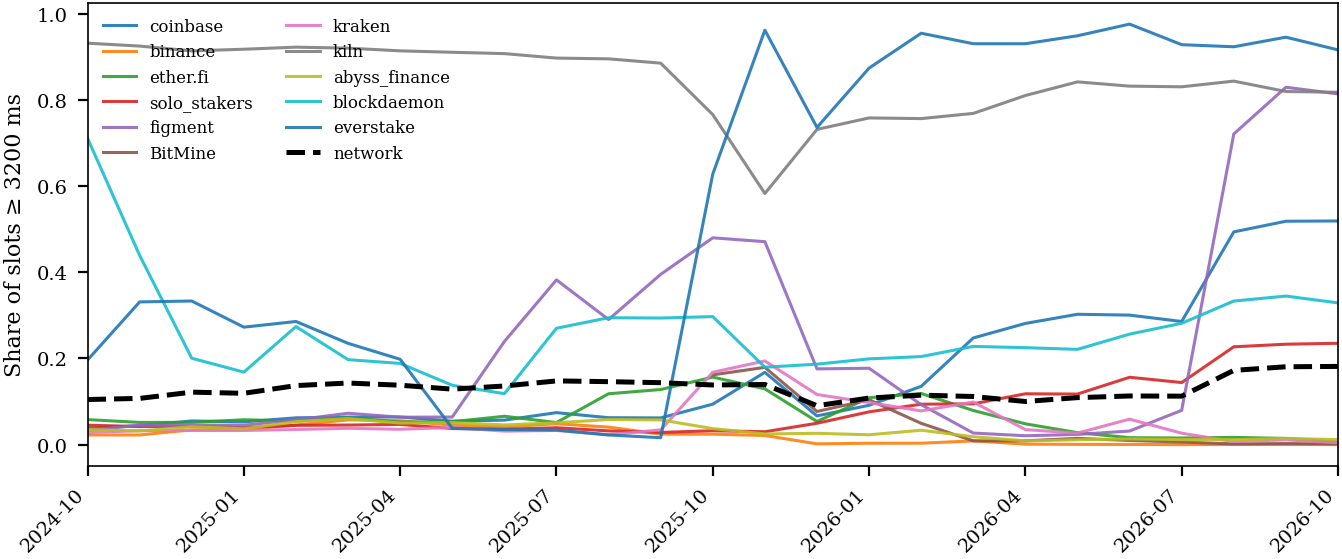

In [17]:
H = pan.pivot(index="source", columns="ym", values="late").loc[by_size_order[:30]]
cmap = plt.cm.Reds.copy()
cmap.set_bad("#EEEEEE")

fig, ax = plt.subplots(figsize=(6.9, max(2.5, len(H) * .11)))
im = ax.imshow(np.ma.masked_invalid(H.values), aspect="auto", cmap=cmap,
               vmin=0, vmax=0.5, interpolation="nearest")
ax.set_yticks(range(len(H)))
ax.set_yticklabels(H.index, fontsize=4)
ax.set_xticks(range(0, len(H.columns), 3))
ax.set_xticklabels([str(H.columns[i]) for i in range(0, len(H.columns), 3)],
                   rotation=45, ha="right", fontsize=6)
fig.colorbar(im, ax=ax, label=f"share of slots ≥ {LATE_MS} ms", pad=.01)
plt.tight_layout()
fig.savefig("fig/late_slot_heatmap.pdf")

fig, ax = plt.subplots(figsize=(6.9, 3.0))
for i, s_ in enumerate(by_size_order[:11]):
    g_ = pan[pan.source == s_].sort_values("ym")
    ax.plot([pos[m_] for m_ in g_.ym], g_.late, lw=1.1, alpha=.9,
            color=plt.cm.tab10(i % 10), label=s_)
ax.plot(range(len(PAN_MONTHS)), [net_late[m_] for m_ in PAN_MONTHS],
        lw=1.8, color="k", ls="--", label="network", zorder=5)
month_ticks(ax, PAN_MONTHS)
ax.set_ylabel(f"Share of slots ≥ {LATE_MS} ms")
ax.margins(x=0)
ax.legend(fontsize=6, ncol=2, frameon=False, loc="upper left")
plt.tight_layout()
fig.savefig("fig/late_slot_line.pdf")

In [18]:
net = (d.assign(late=d.t_ms >= LATE_MS).groupby("ym")
        .agg(net_ms=("t_ms", "median"), net_late=("late", "mean")))

rows = [{"source": "network", "slots": len(d),
         "ms_a": net.net_ms.head(HEAD).mean(), "ms_b": net.net_ms.tail(TAIL).mean(),
         "late_a": net.net_late.head(HEAD).mean(), "late_b": net.net_late.tail(TAIL).mean()}]
for s_, g_ in pan.groupby("source"):
    g_ = g_.sort_values("ym")
    if len(g_) < HEAD + TAIL:
        continue
    a, b = g_.head(HEAD), g_.tail(TAIL)
    rows.append({"source": s_, "slots": int(g_.n.sum()),
                 "first": str(a.ym.iloc[0]), "last": str(b.ym.iloc[-1]),
                 "ms_a": a.med_ms.mean(), "ms_b": b.med_ms.mean(),
                 "late_a": a.late.mean(), "late_b": b.late.mean()})

tab = pd.DataFrame(rows)
tab["d_ms"] = tab.ms_b - tab.ms_a
tab["d_late"] = tab.late_b - tab.late_a
tab["d_late_pp"] = tab.d_late * 100
a_del, b_del = tab.late_a >= DELAY, tab.late_b >= DELAY
tab["grp"] = np.select(
    [tab.source == "network", ~a_del & b_del, a_del & ~b_del, a_del & b_del],
    ["—", "adopter", "exiter", "always"], default="never")
tab = (tab.assign(_o=tab.grp.map({"—": 0, "adopter": 1, "exiter": 2, "always": 3, "never": 4}))
          .sort_values(["_o", "slots"], ascending=[True, False]).drop(columns="_o"))
print(tab.round(3).to_string(index=False))

GROUP_OF  = dict(zip(tab.source, tab.grp))
adopters  = tab[tab.grp == "adopter"].source.tolist()
exiters   = tab[tab.grp == "exiter"].source.tolist()
always    = tab[tab.grp == "always"].source.tolist()
never     = tab[tab.grp == "never"].source.tolist()
NEVER_SET = set(never)

NUM.update({"adopters": len(adopters), "exiters": len(exiters),
            "persistent": len(always), "non_delayers": len(never),
            "adopter_delay_increase_ms": float(tab[tab.grp == "adopter"].d_ms.mean())})
print(f"{len(adopters)} adopters, {len(exiters)} exiters, "
      f"{len(always)} persistent, {len(never)} non-delayers")

                source   slots    ms_a    ms_b  late_a  late_b   first    last     d_ms  d_late  d_late_pp     grp
               network 5434741 2206.50 1938.50   0.106   0.181     NaN     NaN  -268.00   0.075      7.512       —
              coinbase  474183 2311.00 3234.00   0.041   0.519 2024-10 2026-10   923.00   0.478     47.772 adopter
               figment  187627 2165.50 3391.50   0.039   0.822 2024-10 2026-10  1226.00   0.783     78.270 adopter
             everstake   99148 2311.00 3385.00   0.264   0.931 2024-10 2026-10  1074.00   0.667     66.708 adopter
                p2porg   50303 2759.50 3457.50   0.241   0.943 2024-10 2026-10   698.00   0.701     70.147 adopter
          figment_lido   35694 2096.50 3420.50   0.023   0.989 2024-10 2026-10  1324.00   0.966     96.572 adopter
           p2porg_lido   35232 2248.00 3469.50   0.029   0.968 2024-10 2026-10  1221.50   0.940     93.967 adopter
     gateway.fmas_lido   35212 2360.50 3133.00   0.045   0.388 2024-10 2026-10  

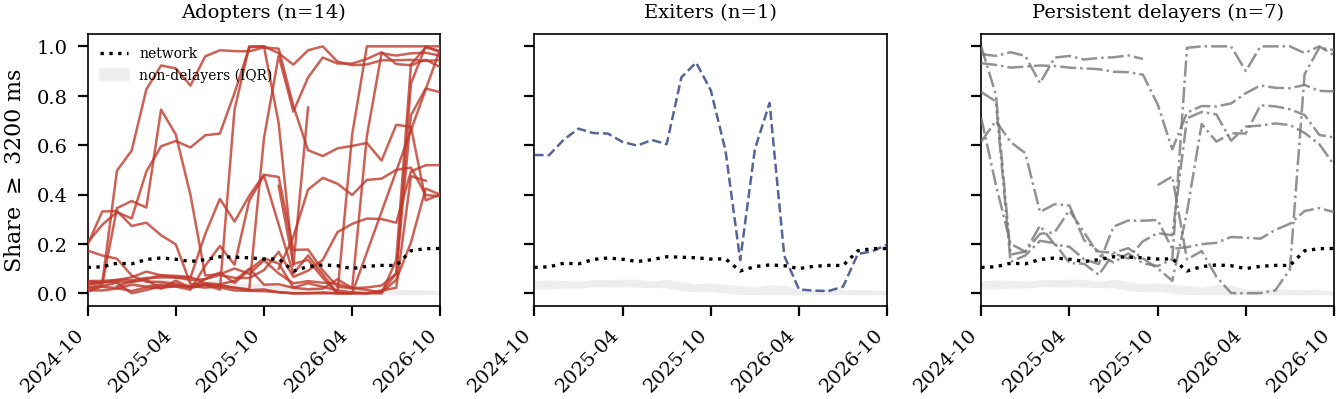

In [19]:
never_iqr = pan[pan.source.isin(never)].groupby("ym").late.quantile([.25, .75]).unstack()
net_line = [net_late[m_] for m_ in PAN_MONTHS]

fig, axes = plt.subplots(1, 3, figsize=(6.9, 2.2), sharex=True, sharey=True)
groups = [("Adopters", adopters, "#C0392B", "-"),
          ("Exiters", exiters, "#2C3E80", "--"),
          ("Persistent delayers", always, "#777777", "-.")]
for ax, (title, members, c, ls) in zip(axes, groups):
    ax.fill_between([pos[m_] for m_ in never_iqr.index], never_iqr[.25], never_iqr[.75],
                    color="#EEEEEE", zorder=1)
    for s_ in members:
        g_ = pan[pan.source == s_].sort_values("ym")
        ax.plot([pos[m_] for m_ in g_.ym], g_.late, lw=.9, ls=ls, color=c,
                alpha=.8, zorder=3)
    ax.plot(range(len(PAN_MONTHS)), net_line, lw=1.2, color="k", ls=":", zorder=4)
    ax.set_title(f"{title} (n={len(members)})", fontsize=7)
    month_ticks(ax, PAN_MONTHS, step=6)
    ax.margins(x=0)
axes[0].set_ylabel(f"Share $\\geq$ {LATE_MS} ms")
axes[0].legend(handles=[Line2D([], [], color="k", lw=1.2, ls=":", label="network"),
                        Patch(color="#EEEEEE", label="non-delayers (IQR)")],
               fontsize=5, frameon=False, loc="upper left")
plt.tight_layout()
fig.savefig("fig/adopters_line.pdf")

In [20]:
GROUP_TITLE = {"adopter": "Adopters", "exiter": "Exiters",
               "always": "Persistent delayers", "never": "Non-delayers"}
SHARE_COLS = [("slots", "Slots", "{:,}"),
              ("late_a", "First", "{:.1%}"),
              ("late_b", "Last", "{:.1%}"),
              ("d_late_pp", "$\\Delta$ (pp)", "{:+.1f}")]
FULL_COLS = SHARE_COLS[:1] + [("ms_a", "First", "{:.0f}"), ("ms_b", "Last", "{:.0f}"),
                              ("d_ms", "$\\Delta$", "{:+.0f}")] + SHARE_COLS[1:]


def write_group_table(df, path, caption, label, cols=SHARE_COLS, star=False):
    env = "table*" if star else "table"
    ncol = len(cols) + 1
    body = []
    for grp in ["adopter", "exiter", "always", "never"]:
        sub = df[df.grp == grp]
        if sub.empty:
            continue
        body.append(f"\\multicolumn{{{ncol}}}{{l}}{{\\textbf{{{GROUP_TITLE[grp]}}} "
                    f"({len(sub)})}} \\\\")
        for _, r_ in sub.iterrows():
            cells = [f.format(r_[k]).replace("%", "\\%") for k, _, f in cols]
            body.append(f"\\quad {tex_escape(r_.source)} & " + " & ".join(cells) + " \\\\")
        body.append("\\addlinespace")
    header = "Operator & " + " & ".join(h for _, h, _ in cols) + " \\\\"
    with open(path, "w") as fh:
        fh.write(f"\\begin{{{env}}}[t]\n\\centering\\footnotesize\n"
                 f"\\caption{{{caption}}}\n\\label{{{label}}}\n"
                 f"\\begin{{tabular}}{{l{'r' * len(cols)}}}\n\\toprule\n"
                 f"{header}\n\\midrule\n" + "\n".join(body[:-1])
                 + f"\n\\bottomrule\n\\end{{tabular}}\n\\end{{{env}}}\n")


delayers = tab[tab.grp.isin(["adopter", "exiter", "always"])]
write_group_table(
    delayers, "tab_main.tex",
    "Operators by delay status. First and Last are averages over each operator's "
    "first two and last two observed months; an operator-month counts as delaying "
    f"when at least {DELAY:.0%} of its blocks arrive {LATE_MS / 1000:.1f}\\,s or "
    "later into the slot.".replace("%", "\\%"),
    "tab:groups")
write_group_table(delayers, "tab_full.tex",
                  "Operators by delay status, with median propagation times.",
                  "tab:groups-full", cols=FULL_COLS, star=True)

In [21]:
def classify(late_ms, delay):
    p = (d.assign(l=d.t_ms >= late_ms)
           .groupby(["source", "ym"])
           .agg(n=("t_ms", "size"), med=("t_ms", "median"), late=("l", "mean"))
           .reset_index()
           .query("n >= @MIN_BLOCKS and med <= @MAX_MED_MS"))
    p = p[p.source.isin(pan.source.unique())].sort_values("ym")
    a = p.groupby("source").head(HEAD).groupby("source").late.mean() >= delay
    b = p.groupby("source").tail(TAIL).groupby("source").late.mean() >= delay
    return {"adopter": int((~a & b).sum()), "exiter": int((a & ~b).sum()),
            "persistent": int((a & b).sum()), "non-delayer": int((~a & ~b).sum())}


SENS_LATE, SENS_DELAY = (3000, 3200, 3400), (0.2, 0.3, 0.4)
sens = pd.DataFrame({(lm, dl): classify(lm, dl)
                     for lm in SENS_LATE for dl in SENS_DELAY}).T
sens.index.names = ["late_ms", "delay"]
print(sens.to_string())

lines = []
for lm in SENS_LATE:
    for j, dl in enumerate(SENS_DELAY):
        r_ = sens.loc[(lm, dl)]
        cells = [f"{dl:.1f}"] + [str(v) for v in r_.values]
        if lm == LATE_MS and abs(dl - DELAY) < 1e-9:
            cells = [f"\\textbf{{{c}}}" for c in cells]
        lines.append(f"{lm if j == 0 else ''} & " + " & ".join(cells) + " \\\\")
    lines.append("\\midrule")
with open("tab_sensitivity.tex", "w") as fh:
    fh.write("\\begin{table}[h]\n\\centering\n"
             "\\caption{Operator classification under alternative thresholds for a late "
             "block and for a delaying operator-month. The main specification is in bold.}\n"
             "\\label{tab:sensitivity}\n\\footnotesize\n\\begin{tabular}{rrrrrr}\n\\toprule\n"
             "Late (ms) & Delay & Adopter & Exiter & Persistent & Non-delayer \\\\\n\\midrule\n"
             + "\n".join(lines[:-1]) + "\n\\bottomrule\n\\end{tabular}\n\\end{table}\n")

               adopter  exiter  persistent  non-delayer
late_ms delay                                          
3000    0.2         12       5          13           78
        0.3         11       4          11           82
        0.4         13       4           9           82
3200    0.2         13       3          10           82
        0.3         14       1           7           86
        0.4         12       2           6           88
3400    0.2         15       1           6           86
        0.3         12       2           5           89
        0.4          9       2           4           93


In [22]:
eb = cached("eb_end", lambda: remote.query_df(f"""
    SELECT validator_index, effective_balance / 1e9 AS eb
    FROM mainnet.fct_validator_balance_daily
    WHERE day_start_date = '{(pd.Timestamp(bounds(*END)[1]) - pd.Timedelta(days=1)).date()}'
      AND status = 'active_ongoing'
      AND validator_index BETWEEN 0 AND 4000000
"""))
eb["grp"] = eb.validator_index.map(SOURCE_OF).map(GROUP_OF)
stake = eb.groupby("grp").eb.sum()
NUM["stake_delaying_eth"]   = float(stake.reindex(["adopter", "always"]).sum())
NUM["stake_delaying_share"] = NUM["stake_delaying_eth"] / float(eb.eb.sum())
print((stake / 1e6).round(2).to_string())
print(f"delaying operators: {NUM['stake_delaying_eth'] / 1e6:.1f} M ETH "
      f"({NUM['stake_delaying_share']:.1%} of active stake)")

grp
adopter     7.10
always      2.65
exiter      0.12
never      23.96
delaying operators: 9.7 M ETH (22.1% of active stake)


## 5.1 MEV Gain from Timing Games

                   blocks  months    first     last  mevboost_rate
source                                                            
coinbase           462765      25  2024-10  2026-10          0.976
figment            183124      25  2024-10  2026-10          0.976
everstake           97449      25  2024-10  2026-10          0.983
p2porg              49789      25  2024-10  2026-10          0.990
p2porg_lido         34970      25  2024-10  2026-10          0.993
gateway.fmas_lido   34879      25  2024-10  2026-10          0.991
figment_lido        34483      25  2024-10  2026-10          0.966
twinstake           31907      25  2024-10  2026-10          0.988
legend              23264      25  2024-10  2026-10          0.995
renzo_protocol      20890      25  2024-10  2026-10          0.945
whale_0xdc8d         6799      20  2024-11  2026-10          0.970
whale_0x16be         3115      16  2025-07  2026-10          0.989
mercado_bitcoin      2925      25  2024-10  2026-10          0

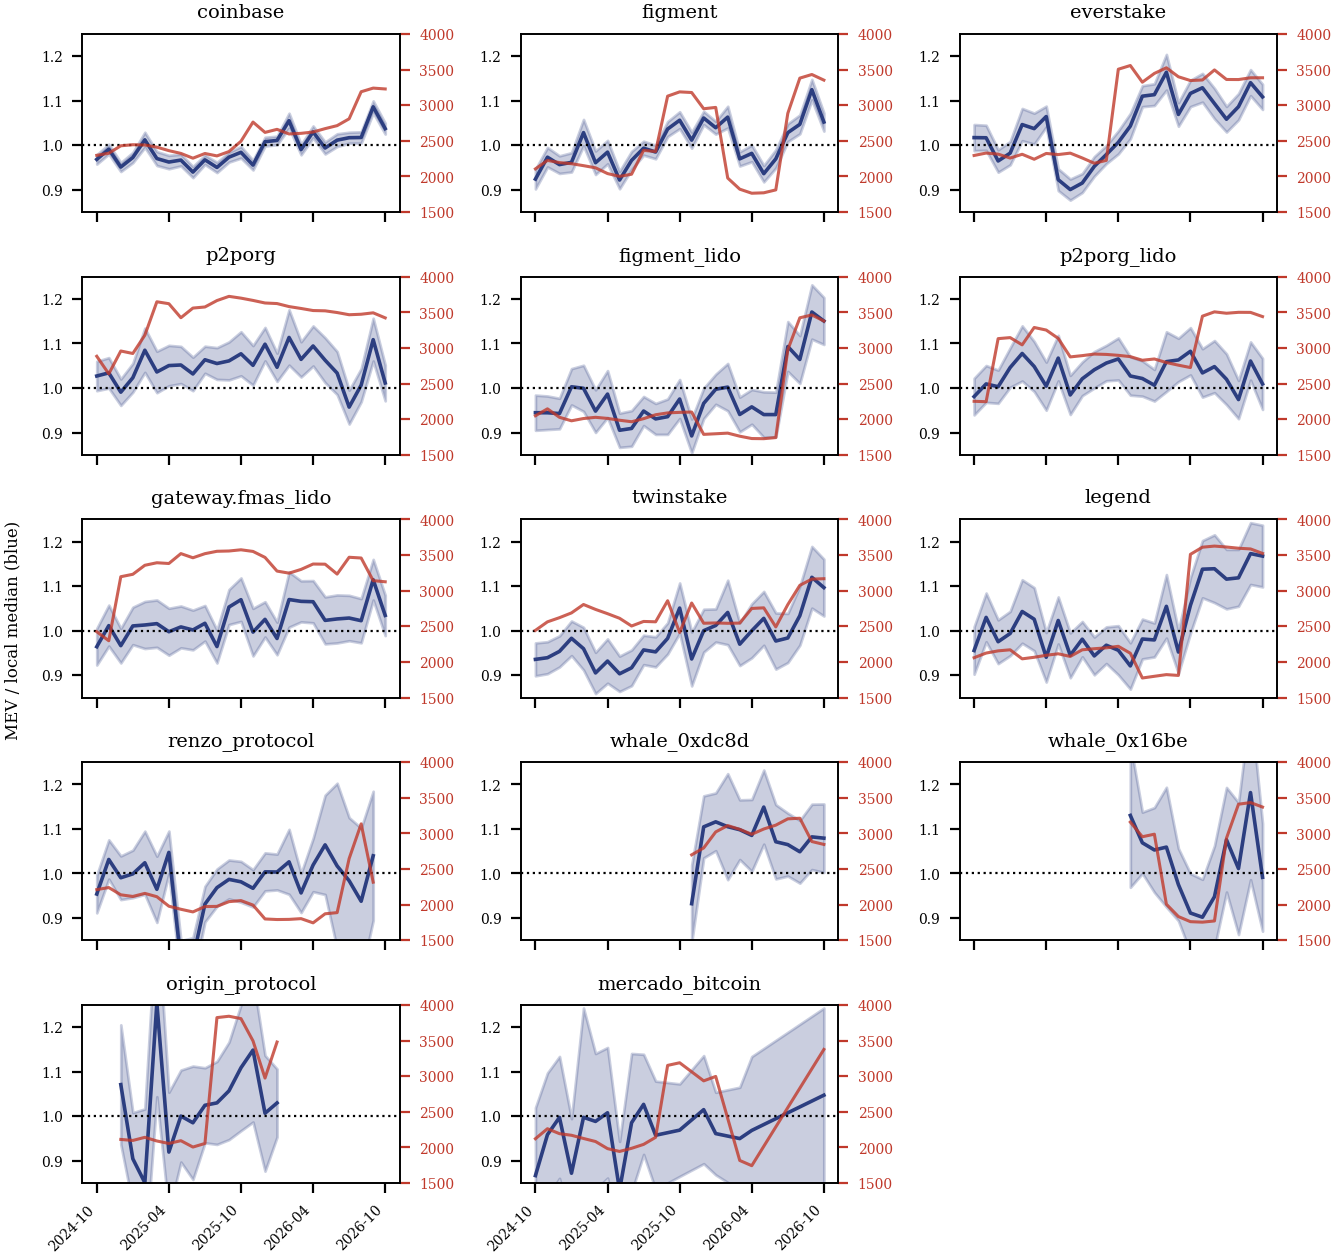

In [23]:
WIN = 7
zz = z.copy()
zz["day"] = zz.ts.dt.floor("D")
base = (zz[zz.source.isin(NEVER_SET)].groupby("day").mev_eth.median()
          .rolling(WIN, center=True, min_periods=WIN // 2).median().rename("base"))
zz = zz.join(base, on="day")
zz["rel"] = zz.mev_eth / zz.base

MEV_MONTHS = sorted(zz.ym.unique())
pos_mev = {m_: i for i, m_ in enumerate(MEV_MONTHS)}


def median_band(series_by_month, min_n):
    """Monthly median with a 95% band from the median's standard error."""
    a = series_by_month.agg(["median", "count", lambda x: x.quantile(.75) - x.quantile(.25)])
    a.columns = ["med", "n", "iqr"]
    a = a[a.n >= min_n]
    se = 1.25 * a.iqr / 1.349 / np.sqrt(a.n)
    return a, se


def plot_operator_mev(ax, s_):
    a, se = median_band(zz[zz.source == s_].groupby("ym").rel, 100)
    xi = [pos_mev[m_] for m_ in a.index]
    ax.fill_between(xi, a.med - 1.96 * se, a.med + 1.96 * se, color="#2C3E80", alpha=.25)
    ax.plot(xi, a.med, lw=1.3, color="#2C3E80")
    ax.axhline(1, c="k", ls=":", lw=.8)
    ax.set_ylim(0.85, 1.25)
    ax.set_title(s_, fontsize=7)
    lp = pan[pan.source == s_].sort_values("ym")
    lp = lp[lp.ym.isin(pos_mev)]
    ax2 = ax.twinx()
    ax2.plot(lp.ym.map(pos_mev), lp.med_ms, lw=1.1, color="#C0392B", alpha=.8)
    ax2.set_ylim(1500, 4000)
    ax2.tick_params(labelsize=5, colors="#C0392B")


ncol = 3
nrow = -(-len(adopters) // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(6.9, 1.3 * nrow), sharex=True, squeeze=False)
for ax, s_ in zip(axes.flat, adopters):
    plot_operator_mev(ax, s_)
for ax in axes.flat[len(adopters):]:
    ax.axis("off")
for ax in axes.flat:
    ax.tick_params(labelsize=5)
for ax in axes[-1]:
    month_ticks(ax, MEV_MONTHS, step=6)
fig.supylabel("MEV / local median (blue)", fontsize=6)
plt.tight_layout()
fig.savefig("fig/adopter_mev.pdf")

adopter_check = (zz[zz.source.isin(adopters)].groupby("source")
                   .agg(blocks=("mev_eth", "size"), months=("ym", "nunique"),
                        first=("ym", "min"), last=("ym", "max"))
                   .join(mevboost_rate.rename("mevboost_rate"))
                   .sort_values("blocks", ascending=False))
print(adopter_check.round(3).to_string())

delaying 1.0807 (n=670,294)  non-delaying 1.0016 (n=3,722,912)
MannwhitneyuResult(statistic=nan, pvalue=nan)


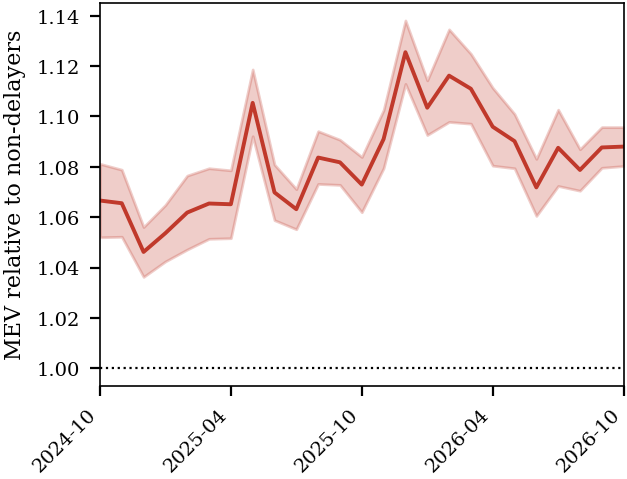

In [24]:
flag = pan.assign(delaying=pan.late >= DELAY)[["source", "ym", "delaying"]]
zm = zz.merge(flag, on=["source", "ym"], how="inner")
never_month = zm[zm.source.isin(NEVER_SET)].groupby("ym").rel.median()
zm["rel_n"] = zm.rel / zm.ym.map(never_month)

a, se = median_band(zm[zm.delaying].groupby("ym").rel_n, 500)
fig, ax = plt.subplots(figsize=(3.33, 2.6))
xi = [pos_mev[m_] for m_ in a.index]
ax.fill_between(xi, a.med - 1.96 * se, a.med + 1.96 * se, color="#C0392B", alpha=.25)
ax.plot(xi, a.med, lw=1.4, color="#C0392B")
ax.axhline(1, c="k", ls=":", lw=.8)
month_ticks(ax, MEV_MONTHS, step=6)
ax.set_ylabel("MEV relative to non-delayers")
ax.margins(x=0)
plt.tight_layout()
fig.savefig("fig/delaying_mev.pdf")

rel_del, rel_non = zm[zm.delaying].rel_n, zm[~zm.delaying].rel_n
NUM["rel_mev_delaying"] = float(rel_del.median())
NUM["rel_mev_non"]      = float(rel_non.median())
print(f"delaying {rel_del.median():.4f} (n={len(rel_del):,})  "
      f"non-delaying {rel_non.median():.4f} (n={len(rel_non):,})")
print(mannwhitneyu(rel_del, rel_non, alternative="greater"))

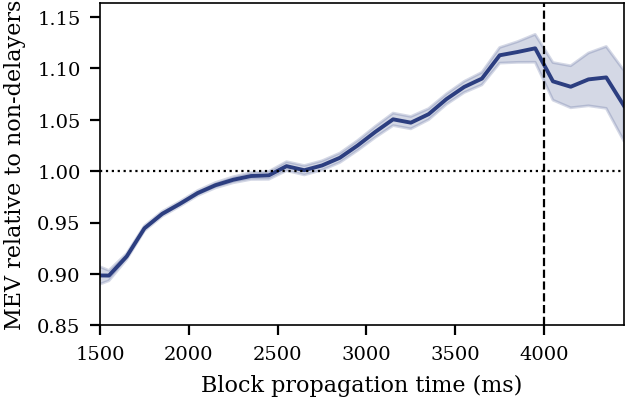

In [25]:
bins100 = np.arange(500, 4501, 100)
a, se = median_band(zz.groupby(pd.cut(zz.t_ms, bins100, labels=bins100[:-1] + 50),
                               observed=True).rel, 500)
x = a.index.astype(float)
fig, ax = plt.subplots(figsize=(3.33, 2.2))
ax.fill_between(x, a.med - 1.96 * se, a.med + 1.96 * se, color="#2C3E80", alpha=.2)
ax.plot(x, a.med, lw=1.4, color="#2C3E80")
ax.axhline(1, c="k", ls=":", lw=.8)
ax.axvline(4000, c="k", ls="--", lw=.8)
ax.set_xlabel("Block propagation time (ms)")
ax.set_ylabel("MEV relative to non-delayers")
ax.margins(x=0)
ax.set_xlim(1500, None)
ax.set_ylim(0.85, None)
plt.tight_layout()
fig.savefig("fig/mev_by_proptime.pdf")

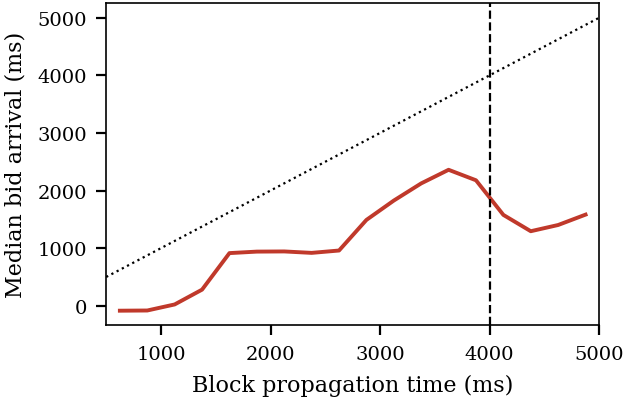

In [29]:
bid = cached("bid", lambda: pull(lambda lo, hi: remote.query_df(f"""
    SELECT slot,
           dateDiff('millisecond', slot_start_date_time, earliest_bid_date_time) AS bid_ms
    FROM mainnet.fct_block_mev
    WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
      AND slot BETWEEN 0 AND 99999999
      AND earliest_bid_date_time IS NOT NULL
""")))
bb = bid.merge(arr[["slot", "t_ms"]], on="slot")
bb = bb[(bb.t_ms < 5000) & (bb.bid_ms > -2000) & (bb.bid_ms < 6000)]
bid_curve = bb.groupby(pd.cut(bb.t_ms, np.arange(500, 5001, 250)), observed=True).bid_ms.median()

fig, ax = plt.subplots(figsize=(3.33, 2.2))
ax.plot([i.mid for i in bid_curve.index], bid_curve.values, lw=1.4, color="#C0392B")
ax.plot([500, 5000], [500, 5000], lw=.8, ls=":", c="k")
ax.axvline(4000, c="k", ls="--", lw=.8)
ax.set_xlabel("Block propagation time (ms)")
ax.set_ylabel("Median bid arrival (ms)")
ax.margins(x=0)
plt.tight_layout()
fig.savefig("fig/bid_timing.pdf")

83 operators, slope +0.063 per s, rho=0.471, p=6.8e-06


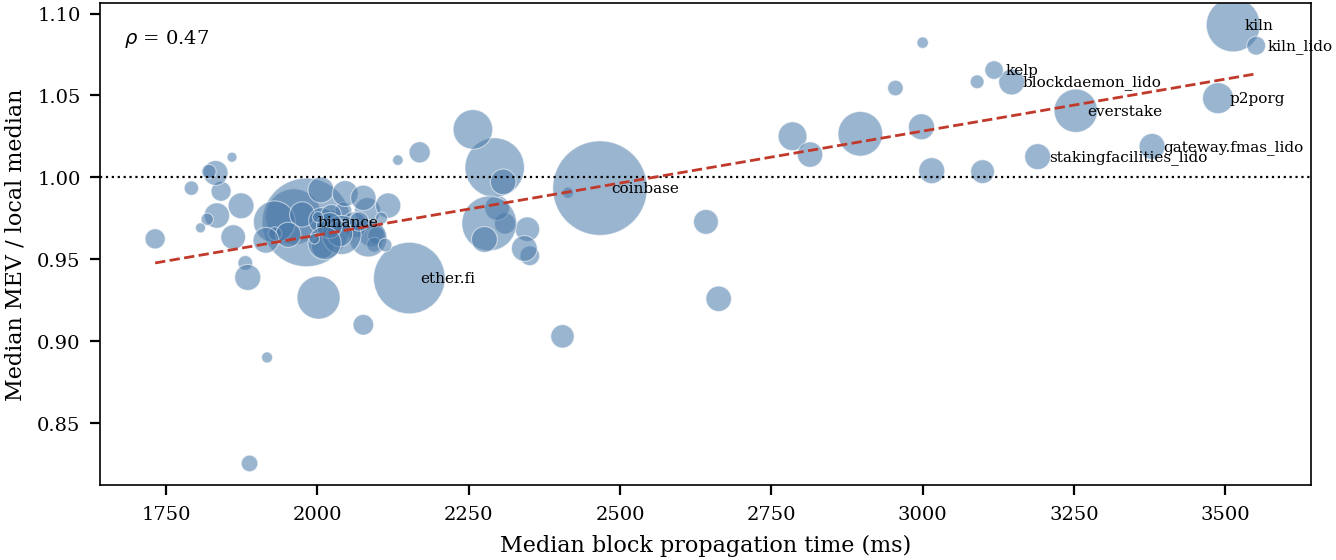

In [30]:
op = (zz.groupby("source")
        .agg(n=("rel", "size"), rel=("rel", "median"), ms=("t_ms", "median"))
        .join(mevboost_rate.rename("mb"))
        .query("n >= 5000 and mb > 0.7"))
coef = np.polyfit(op.ms, op.rel, 1, w=np.sqrt(op.n))
rho_mev, p_mev = spearmanr(op.ms, op.rel)
NUM["mev_scatter_operators"] = len(op)
NUM["mev_scatter_rho"], NUM["mev_scatter_p"] = float(rho_mev), float(p_mev)
print(f"{len(op)} operators, slope {coef[0] * 1000:+.3f} per s, rho={rho_mev:.3f}, p={p_mev:.1e}")

fig, ax = plt.subplots(figsize=(6.9, 3.0))
ax.scatter(op.ms, op.rel, s=op.n / 400, color="#4878A8", alpha=.55,
           edgecolors="white", linewidths=.4, zorder=2)
xs = np.array([op.ms.min(), op.ms.max()])
ax.plot(xs, np.polyval(coef, xs), lw=1, ls="--", color="#C0392B", zorder=3)
ax.text(.02, .95, f"$\\rho$ = {rho_mev:.2f}", transform=ax.transAxes, fontsize=7, va="top")
for name_, r_ in op[(op.ms > 3100) | (op.n > op.n.quantile(.97))].iterrows():
    ax.annotate(name_, (r_.ms, r_.rel), xytext=(4, 0), textcoords="offset points",
                fontsize=5.5, va="center")
ax.axhline(1, c="k", ls=":", lw=.8)
ax.set_xlabel("Median block propagation time (ms)")
ax.set_ylabel("Median MEV / local median")
plt.tight_layout()
fig.savefig("fig/mev_vs_proptime.pdf")

In [31]:
mev_month = (zm.groupby(["ym", "delaying"]).mev_eth.median().unstack()
               .rename(columns={True: "delay", False: "nodelay"}))
mev_month["gain_eth"]  = mev_month.delay - mev_month.nodelay
mev_month["gain_pct"]  = (mev_month.delay / mev_month.nodelay - 1) * 100
mev_month["n_delay"]   = zm[zm.delaying].groupby("ym").size()
mev_month["total_eth"] = mev_month.gain_eth * mev_month.n_delay
NUM["gain_full_median_eth"] = float(mev_month.gain_eth.median())
NUM["gain_full_total_eth"]  = float(mev_month.total_eth.sum())
print(mev_month.round(4).to_string())

with open("tab_mev_gain.tex", "w") as fh:
    fh.write("\\begin{table*}[t]\n\\centering\\footnotesize\n"
             "\\caption{Median MEV payment of delaying and non-delaying blocks, by month. "
             "Gain is the difference between the two medians; the total applies that gain "
             "to every block proposed by a delaying operator-month.}\n\\label{tab:mev-gain}\n"
             "\\begin{tabular}{lrrrrrr}\n\\toprule\n"
             "Month & \\multicolumn{2}{c}{Median MEV (ETH)} & \\multicolumn{2}{c}{Gain} & "
             "Blocks & Total \\\\\n\\cmidrule(lr){2-3}\\cmidrule(lr){4-5}\n"
             " & No delay & Delay & ETH & \\% & & (ETH) \\\\\n\\midrule\n")
    for ym_, r_ in mev_month.iterrows():
        fh.write(f"{ym_} & {r_.nodelay:.4f} & {r_.delay:.4f} & {r_.gain_eth:.4f} & "
                 f"{r_.gain_pct:.1f} & {int(r_.n_delay):,} & {r_.total_eth:.1f} \\\\\n")
    fh.write("\\midrule\n"
             f"Median / sum & & & {mev_month.gain_eth.median():.4f} & "
             f"{mev_month.gain_pct.median():.1f} & {int(mev_month.n_delay.sum()):,} & "
             f"{mev_month.total_eth.sum():.0f} \\\\\n"
             "\\bottomrule\n\\end{tabular}\n\\end{table*}\n")

delaying  nodelay   delay  gain_eth  gain_pct  n_delay  total_eth
ym                                                               
2024-10    0.0471  0.0507    0.0037    7.7570    14132    51.6057
2024-11    0.0452  0.0484    0.0032    7.0068    18106    57.3757
2024-12    0.0336  0.0352    0.0016    4.6779    30259    47.5978
2025-01    0.0311  0.0330    0.0019    6.1123    26196    49.8192
2025-02    0.0224  0.0238    0.0014    6.4673    25241    36.4869
2025-03    0.0188  0.0201    0.0013    6.9531    27538    36.0599
2025-04    0.0202  0.0214    0.0013    6.2054    27096    33.9018
2025-05    0.0246  0.0274    0.0027   11.0496    23065    62.7900
2025-06    0.0222  0.0239    0.0017    7.7860    26848    46.4234
2025-07    0.0239  0.0256    0.0017    7.1646    34490    58.9648
2025-08    0.0158  0.0171    0.0013    8.3223    23046    30.2138
2025-09    0.0117  0.0127    0.0010    8.2033    29660    28.4691
2025-10    0.0117  0.0125    0.0009    7.4418    27429    23.8156
2025-11   

## 5.2 Cost to the Delaying Proposer: Reorgs

          rate        n     pct
t_ms                           
875   0.000000     1941   0.000
1125  0.000383    10432   0.038
1375  0.000329    39543   0.033
1625  0.000465   571746   0.047
1875  0.000344  1144032   0.034
2125  0.000227  1040535   0.023
2375  0.000289   618413   0.029
2625  0.000329   373467   0.033
2875  0.000421   313850   0.042
3125  0.000312   230736   0.031
3375  0.000234   277609   0.023
3625  0.000254   228738   0.025
3875  0.000397    80671   0.040
4125  0.001318    22011   0.132
4375  0.041654     9507   4.165
4625  0.107121     4985  10.712
4875  0.121697     2876  12.170


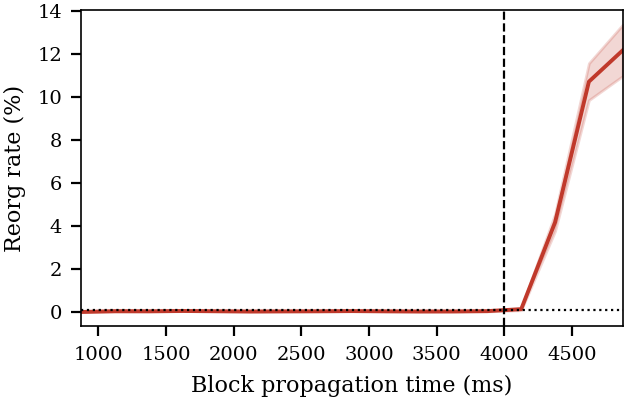

In [32]:
bins250 = np.arange(500, 5001, 250)
reorg_bin = (z.groupby(pd.cut(z.t_ms, bins250, labels=bins250[:-1] + 125), observed=True)
               .orphaned.agg(["mean", "size"]))
reorg_bin.columns = ["rate", "n"]
reorg_bin = reorg_bin[reorg_bin.n >= 500]
se = np.sqrt(reorg_bin.rate * (1 - reorg_bin.rate) / reorg_bin.n)
x = reorg_bin.index.astype(float)
print(reorg_bin.assign(pct=(reorg_bin.rate * 100).round(3)).to_string())

fig, ax = plt.subplots(figsize=(3.33, 2.2))
ax.fill_between(x, (reorg_bin.rate - 1.96 * se) * 100, (reorg_bin.rate + 1.96 * se) * 100,
                color="#C0392B", alpha=.2)
ax.plot(x, reorg_bin.rate * 100, lw=1.4, color="#C0392B")
ax.axhline(z.orphaned.mean() * 100, c="k", ls=":", lw=.8)
ax.axvline(4000, c="k", ls="--", lw=.8)
ax.set_xlabel("Block propagation time (ms)")
ax.set_ylabel("Reorg rate (%)")
ax.margins(x=0)
plt.tight_layout()
fig.savefig("fig/reorg_by_proptime.pdf")

83 operators, network 0.078%, rho=0.430 p=4.9e-05, slope 0.0394 pp/s CI [0.0222, 0.0566]


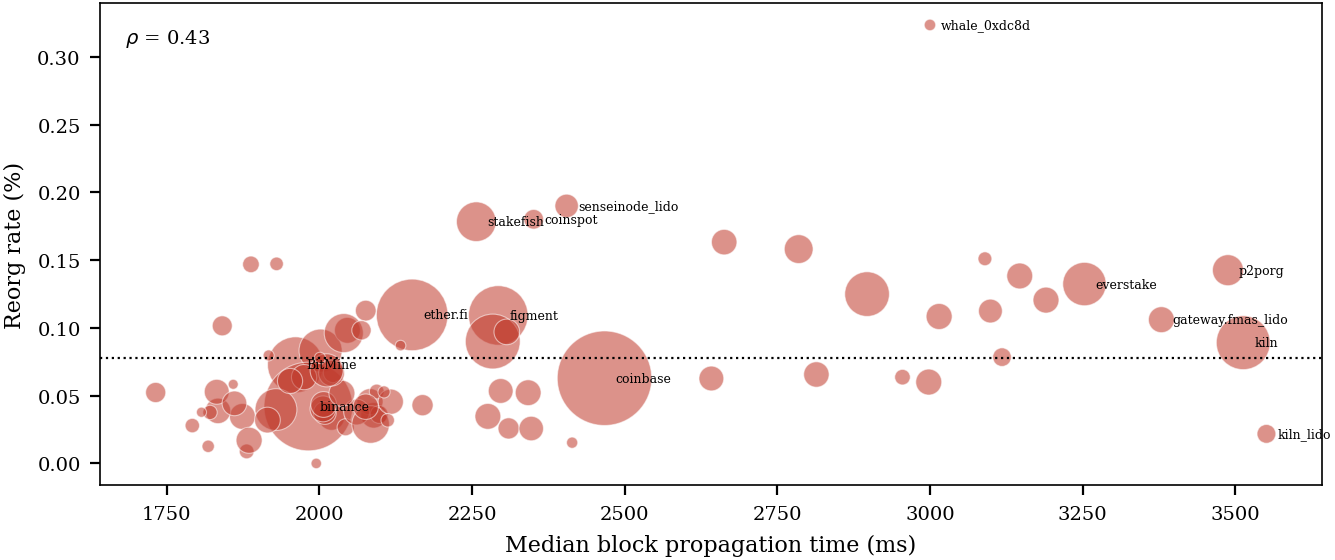

In [33]:
rg = (z.groupby("source")
        .agg(n=("orphaned", "size"), reorg=("orphaned", "mean"), ms=("t_ms", "median"))
        .join(mevboost_rate.rename("mb"))
        .query("n >= 5000 and mb > 0.7"))
rg["reorg_pct"] = rg.reorg * 100
rho_rg, p_rg = spearmanr(rg.ms, rg.reorg_pct)

reorg_fit = sm.WLS(rg.reorg_pct, sm.add_constant((rg.ms / 1000).rename("sec")),
                   weights=rg.n).fit()
reorg_slope = reorg_fit.params["sec"]                       # pp per second
reorg_ci = reorg_fit.conf_int().loc["sec"].tolist()

NUM.update({"reorg_operators": len(rg), "reorg_network_pct": float(z.orphaned.mean() * 100),
            "reorg_rho": float(rho_rg), "reorg_p": float(p_rg),
            "reorg_slope_pp_per_s": float(reorg_slope), "reorg_slope_ci": reorg_ci})
print(f"{len(rg)} operators, network {z.orphaned.mean() * 100:.3f}%, "
      f"rho={rho_rg:.3f} p={p_rg:.1e}, slope {reorg_slope:.4f} pp/s "
      f"CI [{reorg_ci[0]:.4f}, {reorg_ci[1]:.4f}]")

fig, ax = plt.subplots(figsize=(6.9, 3.0))
ax.scatter(rg.ms, rg.reorg_pct, s=rg.n / 400, color="#C0392B", alpha=.55,
           edgecolors="white", linewidths=.4, zorder=2)
ax.axhline(z.orphaned.mean() * 100, c="k", ls=":", lw=.8)
ax.text(.02, .95, f"$\\rho$ = {rho_rg:.2f}", transform=ax.transAxes, fontsize=7, va="top")
for name_, r_ in rg[(rg.ms > 3200) | (rg.n > rg.n.quantile(.95)) | (rg.reorg_pct > 0.17)].iterrows():
    ax.annotate(name_, (r_.ms, r_.reorg_pct), xytext=(4, 0), textcoords="offset points",
                fontsize=4.5, va="center")
ax.set_xlabel("Median block propagation time (ms)")
ax.set_ylabel("Reorg rate (%)")
plt.tight_layout()
fig.savefig("fig/reorg_vs_proptime.pdf")

## 5.3 Cost to Attesters: Head Votes

In [34]:
att_raw = cached("attestation", lambda: pull(lambda lo, hi: remote.query_df(f"""
    SELECT slot, sum(votes_head) AS votes_head, sum(votes_max) AS votes_max
    FROM mainnet.fct_attestation_correctness
    WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
      AND slot BETWEEN 0 AND 99999999
    GROUP BY slot
""")))
att_slot = arr[["slot", "t_ms", "ts", "ym"]].merge(in_window(att_raw), on="slot")
att_slot["head_rate"] = att_slot.votes_head / att_slot.votes_max
NUM["att_first_slot"] = int(att_slot.slot.min())
print(f"{len(att_slot):,} slots, {att_slot.slot.min()} to {att_slot.slot.max()} "
      f"({att_slot.ts.min().date()} to {att_slot.ts.max().date()})")

3,843,130 slots, 11696962 to 15555597 (2025-05-14 to 2026-10-31)


In [35]:
# (needs database access; skipped offline)
if not OFFLINE:
    chk_slot = int(att_slot.loc[att_slot.t_ms.between(3750, 4000), "slot"].iloc[0])
    chk_ts = pd.to_datetime(GENESIS + chk_slot * SLOT_SEC, unit="s")
    print(remote.query_df(f"""
        SELECT slot_distance, inclusion_distance, status, count() AS n
        FROM mainnet.fct_attestation_correctness_by_validator
        WHERE slot_start_date_time = '{chk_ts}' AND slot = {chk_slot}
        GROUP BY slot_distance, inclusion_distance, status
        ORDER BY n DESC
    """).to_string())
    print(att_slot.loc[att_slot.slot == chk_slot,
                       ["t_ms", "votes_head", "votes_max"]].to_string())

   slot_distance  inclusion_distance     status      n
0              0                   1  canonical  31829
1              1                   2  canonical    531
2              1                   1  canonical    336
3              0                   2  canonical    189
4           <NA>                <NA>     missed    111
   t_ms  votes_head  votes_max
4  3985       32018      32996


        rate       n
t_ms                
625   0.9962   18328
875   0.9957   19944
1125  0.9947   24079
1375  0.9954   48871
1625  0.9965  590059
1875  0.9962  953243
2125  0.9953  682919
2375  0.9937  353449
2625  0.9928  245945
2875  0.9924  253230
3125  0.9887  177390
3375  0.9864  221794
3625  0.9648  164077
3875  0.8906   55463
4125  0.7152   14475
4375  0.5406    5733
4625  0.4895    3154
4875  0.4922    2022


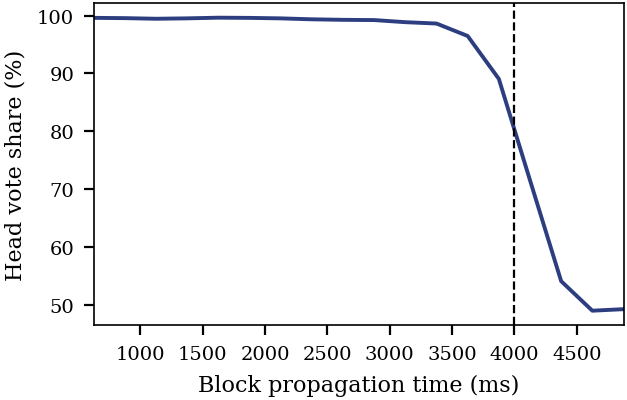

In [36]:
head_bin = (att_slot.groupby(pd.cut(att_slot.t_ms, bins250, labels=bins250[:-1] + 125),
                             observed=True)
                    .agg(rate=("head_rate", "mean"), n=("head_rate", "size")))
head_bin = head_bin[head_bin.n >= 500]
print(head_bin.round(4).to_string())

fig, ax = plt.subplots(figsize=(3.33, 2.2))
ax.plot(head_bin.index.astype(float), head_bin.rate * 100, lw=1.4, color="#2C3E80")
ax.axvline(4000, c="k", ls="--", lw=.8)
ax.set_xlabel("Block propagation time (ms)")
ax.set_ylabel("Head vote share (%)")
ax.margins(x=0)
plt.tight_layout()
fig.savefig("fig/head_vote.pdf")

In [37]:
bal_month = cached("balance_monthly", lambda: pull(lambda lo, hi: remote.query_df(f"""
    SELECT toStartOfMonth(day_start_date) AS m,
           avg(effective_balance) / 1e9 AS avg_eb,
           sum(effective_balance) / 1e9 AS total_eb,
           count() AS n
    FROM mainnet.fct_validator_balance_daily
    WHERE day_start_date >= '{lo}' AND day_start_date < '{hi}'
      AND day_start_date = toStartOfMonth(day_start_date)
      AND status = 'active_ongoing'
    GROUP BY m
""")))
bal_month["ym"] = pd.to_datetime(bal_month.m).dt.to_period("M")
# head reward = 14/64 * base reward, base reward = 64 * e / sqrt(E)  (Gwei)
bal_month["head_eth"] = (bal_month.avg_eb * 1e9 * 64 / np.sqrt(bal_month.total_eb * 1e9)
                         * 14 / 64 / 1e9)
print(bal_month[["ym", "avg_eb", "total_eb", "head_eth"]].to_string(index=False))

cost_start = att_slot.ym.min()
NUM["avg_eb_start"] = float(bal_month.loc[bal_month.ym == cost_start, "avg_eb"].iloc[0])
NUM["avg_eb_end"]   = float(bal_month.loc[bal_month.ym == pd.Period(f"{END[0]}-{END[1]:02d}"),
                                          "avg_eb"].iloc[0])

     ym    avg_eb   total_eb  head_eth
2024-10 31.999607 34470137.0  0.000002
2024-11 31.999644 34458209.0  0.000002
2024-12 31.999633 34371254.0  0.000002
2025-01 31.999627 33994612.0  0.000002
2025-02 31.999607 33771681.0  0.000002
2025-03 31.999594 33606486.0  0.000002
2025-04 31.999594 34099023.0  0.000002
2025-05 31.999590 34141739.0  0.000002
2025-06 32.492901 34358123.0  0.000002
2025-07 32.601647 35412887.0  0.000002
2025-08 32.824988 35129007.0  0.000002
2025-09 33.384986 34825582.0  0.000003
2025-10 34.484739 33699280.0  0.000003
2025-11 35.074510 33282343.0  0.000003
2025-12 35.514616 34186511.0  0.000003
2026-01 36.353835 35457713.0  0.000003
2026-02 37.591751 36705751.0  0.000003
2026-03 38.864165 37224991.0  0.000003
2026-04 41.617809 38410949.0  0.000003
2026-05 42.774016 38165287.0  0.000003
2026-06 43.969287 39132446.0  0.000003
2026-07 45.417057 40063703.0  0.000003
2026-08 46.455128 41405502.0  0.000003
2026-09 47.209081 42697120.0  0.000003
2026-10 50.196062 4289097

In [38]:
base_rate = att_slot.loc[att_slot.t_ms.between(*HEAD_BASE_MS), "head_rate"].mean()
att_slot = att_slot.merge(bal_month[["ym", "head_eth"]], on="ym", how="left")
att_slot["lost_votes"] = (base_rate - att_slot.head_rate).clip(lower=0) * att_slot.votes_max
att_slot["lost_eth"] = att_slot.lost_votes * att_slot.head_eth

lost_pre = att_slot.loc[att_slot.t_ms < 4000, "lost_votes"].sum()
lost_post = att_slot.loc[att_slot.t_ms >= 4000, "lost_votes"].sum()
NUM["head_base_rate"] = float(base_rate)
NUM["lost_share_before_4s"] = float(lost_pre / (lost_pre + lost_post))
print(f"baseline head rate {base_rate:.5f}; "
      f"{NUM['lost_share_before_4s']:.1%} of lost head votes come from blocks before 4 s")

baseline head rate 0.99630; 62.0% of lost head votes come from blocks before 4 s


In [39]:
cc = att_slot.merge(zm[["slot", "delaying", "mev_eth"]], on="slot", how="inner")
cost_month = (cc.groupby(["ym", "delaying"])
                .agg(mev=("mev_eth", "median"), lost=("lost_eth", "mean")).unstack())
gain_m = cost_month[("mev", True)] - cost_month[("mev", False)]
att_m  = cost_month[("lost", True)] - cost_month[("lost", False)]
n_m    = cc[cc.delaying].groupby("ym").size()
N      = int(n_m.sum())


def weighted(diff_by_month, weights=n_m):
    return float((diff_by_month * weights).sum() / weights.sum())


gain     = weighted(gain_m)
att_loss = weighted(att_m)
print(f"{len(cc):,} blocks, {N:,} delayed")
print(f"MEV gain       {gain:.6f} ETH/block  total {gain * N:7.1f} ETH")
print(f"attester loss  {att_loss:.6f} ETH/block  total {att_loss * N:7.1f} ETH  "
      f"{att_loss / gain:.2f}x")

# pooled comparison, to show why we compare within months
pooled = cc[cc.delaying].mev_eth.median() - cc[~cc.delaying].mev_eth.median()
NUM["gain_pooled"] = float(pooled)
print(f"pooled (not within-month) gain: {pooled:.6f} ETH")

3,073,649 blocks, 492,053 delayed
MEV gain       0.001005 ETH/block  total   494.5 ETH
attester loss  0.001934 ETH/block  total   951.8 ETH  1.92x
pooled (not within-month) gain: 0.000544 ETH


## 5.4 Who Bears the Attester Loss?

In [40]:
def by_attester(late_rng, norm_rng=BURDEN_NORM, chunk=20_000):
    """Return a pull() function that counts head-correct votes per operator."""
    def fn(lo, hi):
        m_ = att_slot[(att_slot.ts >= lo) & (att_slot.ts < hi)]
        late = m_.loc[m_.t_ms.between(*late_rng), "slot"]
        if len(late) == 0:
            return None
        norm = m_.loc[m_.t_ms.between(*norm_rng), "slot"]
        norm = norm.sample(min(len(norm), len(late)), random_state=0)
        out = []
        for tag, sl in [("late", late), ("norm", norm)]:
            parts = []
            for i in range(0, len(sl), chunk):
                ids = ",".join(map(str, sl.iloc[i:i + chunk]))
                parts.append(remote.query_df(f"""
                    SELECT attesting_validator_index AS v,
                           countIf(slot_distance = 0) AS ok, count() AS n
                    FROM mainnet.fct_attestation_correctness_by_validator
                    WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
                      AND status = 'canonical'
                      AND slot IN ({ids})
                    GROUP BY v
                """))
            q_ = pd.concat(parts).groupby("v")[["ok", "n"]].sum().reset_index()
            q_["source"] = q_.v.map(SOURCE_OF).fillna("unlabeled")
            g_ = q_.groupby("source")[["ok", "n"]].sum().reset_index()
            g_["cond"] = tag
            out.append(g_)
        return pd.concat(out)
    return fn


BURDEN_TITLE = {"adopter": "Adopters", "always": "Persistent delayers",
                "never": "Non-delayers", "solo": "Solo stakers",
                "rp": "Rocket Pool", "unclassified": "Unclassified"}
BURDEN_ORDER = list(BURDEN_TITLE)


def attester_burden(counts, att_total):
    """Per-operator and per-group share of votes and of the excess head-vote loss."""
    c = counts.groupby(["source", "cond"])[["ok", "n"]].sum().unstack("cond")
    miss_late = 1 - c[("ok", "late")] / c[("n", "late")]
    miss_norm = 1 - c[("ok", "norm")] / c[("n", "norm")]
    src = pd.DataFrame({"miss_late": miss_late * 100, "miss_norm": miss_norm * 100,
                        "excess_pp": (miss_late - miss_norm) * 100,
                        "duty": c[("n", "late")],
                        "lost": (miss_late - miss_norm).clip(lower=0) * c[("n", "late")]})
    src["vote"] = src.duty / src.duty.sum() * 100
    src["loss"] = src.lost / src.lost.sum() * 100
    src["burden"] = src.loss / src.vote
    src["group"] = src.index.map(GROUP_OF).fillna("unclassified")
    src.loc[src.index == "solo_stakers", "group"] = "solo"
    src.loc[src.index == "rocketpool", "group"] = "rp"
    grp = src.groupby("group")[["duty", "lost"]].sum()
    grp["vote"] = grp.duty / grp.duty.sum() * 100
    grp["loss"] = grp.lost / grp.lost.sum() * 100
    grp["burden"] = grp.loss / grp.vote
    grp["eth"] = grp.loss / 100 * att_total
    return src, grp.reindex(BURDEN_ORDER)


burden_counts = cached(f"burden_{BURDEN_LATE[0]}_{BURDEN_LATE[1]}",
                       lambda: pull(by_attester(BURDEN_LATE)))
burden_src, burden_grp = attester_burden(burden_counts, att_loss * N)
NUM["burden"] = burden_grp.burden.round(3).to_dict()
NUM["burden_vote_share"] = burden_grp.vote.round(2).to_dict()
NUM["burden_loss_share"] = burden_grp.loss.round(2).to_dict()
print(burden_grp[["vote", "loss", "burden", "eth"]].round(2).to_string())

               vote   loss  burden     eth
group                                     
adopter       18.07   8.32    0.46   79.15
always         6.48   4.60    0.71   43.81
never         56.84  56.29    0.99  535.75
solo           3.09   7.45    2.41   70.91
rp             1.70   3.65    2.15   34.74
unclassified  13.42  19.67    1.47  187.22


In [41]:
rows = "\n".join(f"{BURDEN_TITLE[g_]} & {x_.vote:.1f} & {x_.loss:.1f} & {x_.burden:.2f} & "
                 f"{x_.eth:.0f} \\\\" for g_, x_ in burden_grp.iterrows())
with open("tab_burden.tex", "w") as fh:
    fh.write("\\begin{table}[t]\n\\centering\n"
             f"\\caption{{Who bears the head-vote loss on late blocks "
             f"({BURDEN_LATE[0] / 1000:.1f}--{BURDEN_LATE[1] / 1000:.0f}\\,s). Vote is each "
             "group's share of attestations cast in late-block slots; Loss is its share of the "
             "excess head-vote loss; Burden is their ratio (1 = proportional); ETH allocates "
             "the total attester loss in proportion to Loss. Exiters omitted.}\n"
             "\\label{tab:burden}\n\\footnotesize\n\\begin{tabular}{lrrrr}\n\\toprule\n"
             "Attester group & Vote (\\%) & Loss (\\%) & Burden & ETH \\\\\n\\midrule\n"
             + rows + "\n\\bottomrule\n\\end{tabular}\n\\end{table}\n")

big = burden_src[burden_src.duty >= 1e6].sort_values("vote", ascending=False).head(50)
rows = "\n".join(f"{tex_escape(k)} & {x_.miss_late:.2f} & {x_.miss_norm:.2f} & "
                 f"{x_.excess_pp:.2f} & {x_.vote:.2f} & {x_.loss:.2f} & {x_.burden:.2f} \\\\"
                 for k, x_ in big.iterrows())
with open("tab_burden_all.tex", "w") as fh:
    fh.write("\\begin{table*}[t]\n\\centering\n"
             "\\caption{Head-vote loss by attesting operator (operators with at least $10^6$ "
             "votes in late-block slots).}\n\\label{tab:burden-all}\n\\footnotesize\n"
             "\\begin{tabular}{lrrrrrr}\n\\toprule\n"
             "Operator & \\multicolumn{2}{c}{Head miss (\\%)} & Excess & Vote & Loss & Burden \\\\\n"
             "\\cmidrule(lr){2-3}\n & late & on-time & (pp) & (\\%) & (\\%) & \\\\\n\\midrule\n"
             + rows + "\n\\bottomrule\n\\end{tabular}\n\\end{table*}\n")

## 5.5 Cost to the Next Proposer

In [42]:
cur = zm.loc[zm.slot.isin(cc.slot), ["slot", "ym", "delaying"]]
nxt = zm[["slot", "delaying", "mev_eth"]].rename(
    columns={"delaying": "next_delaying", "mev_eth": "mev_next"})
nxt["slot"] -= 1                              # align block N+1 with block N
pairs = cur.merge(nxt, on="slot", how="inner").query("not next_delaying")

next_month = pairs.groupby(["ym", "delaying"]).mev_next.median().unstack()
next_mev_m = next_month[False] - next_month[True]
next_n = pairs[pairs.delaying].groupby("ym").size()
next_mev_loss = weighted(next_mev_m, next_n)
NUM["next_mev_pairs"] = int(next_n.sum())
print(f"next-proposer MEV loss {next_mev_loss:.6f} ETH/block "
      f"({next_mev_loss / gain:.2f}x gain), n={next_n.sum():,} pairs")

next-proposer MEV loss 0.000849 ETH/block (0.84x gain), n=314,048 pairs


In [43]:
late_incl = cached("late_inclusion", lambda: pull(lambda lo, hi: remote.query_df(f"""
    SELECT slot, countIf(inclusion_distance >= 2) AS late_incl
    FROM mainnet.fct_attestation_correctness_by_validator
    WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
      AND status = 'canonical'
      AND slot BETWEEN 0 AND 99999999
    GROUP BY slot
""")))
ci = cc.merge(late_incl, on="slot")
# next proposer forgoes 1/7 of the source+target reward (40/64 B = head_eth * 40/14)
ci["inc_eth"] = ci.late_incl * ci.head_eth * 40 / 14 / 7
inc_month = ci.groupby(["ym", "delaying"]).inc_eth.mean().unstack()
inc_m = inc_month[True] - inc_month[False]
inc_loss = weighted(inc_m)
print(f"next-proposer late-inclusion loss {inc_loss:.6f} ETH/block ({inc_loss / gain:.2f}x gain)")

next-proposer late-inclusion loss 0.000114 ETH/block (0.11x gain)


## Summary: gain vs. costs (Table `tab:cost`, Figure `fig:gain-cost`)

In [44]:
block_value = float(z.mev_eth.median())
delay_s = NUM["adopter_delay_increase_ms"] / 1000
reorg_cost = reorg_slope * delay_s / 100 * block_value      # ETH per delayed block

channels = [
    # label, paid by, goes to, ETH/block (signed), months series, section label
    ("MEV gain", "---", "proposer", gain, gain_m, "sec:mev"),
    ("Reorg", "proposer", "unissued", -reorg_cost, None, "sec:reorg"),
    ("Head votes", "attesters", "unissued", -att_loss, att_m, "sec:head"),
    ("Head inclusion reward", "next proposer", "unissued", -att_loss / 7, att_m, "sec:next"),
    ("Late inclusion", "next proposer", "proposer of $N{+}2$", -inc_loss, inc_m, "sec:next"),
    ("MEV", "next proposer", "delaying proposer", -next_mev_loss, next_mev_m, "sec:next"),
]


def eth_fmt(v):
    return f"${v:+.6f}$" if abs(v) < 1e-4 else f"${v:+.5f}$"


summary = []
for label, paid, goes, v, series, sec in channels:
    months_ok = "---" if series is None else f"{int((series > 0).sum())}/{int(series.notna().sum())}"
    is_gain = label == "MEV gain"
    ratio = "---" if is_gain else f"{-v / gain:.3f}"      # positive = cost to that party
    total = (v if is_gain else -v) * N                   # positive = gain / cost as labeled
    summary.append((label, paid, goes, v, ratio, total, months_ok, sec))
    print(f"{label:22s} {v:+.6f} ETH/block  x gain {ratio:>6}  total {total:7.1f} ETH  "
          f"months {months_ok}")

cost_rows = []
for i, (label, paid, goes, v, ratio, total, months_ok, sec) in enumerate(summary):
    cost_rows.append(f"{label} & {paid} & {goes} & {eth_fmt(v)} & {ratio} & {total:.1f} & "
                     f"{months_ok} & \\ref{{{sec}}} \\\\")
    if i in (0, 1, 2):
        cost_rows.append("\\midrule")
with open("tab_cost.tex", "w") as fh:
    fh.write("\\begin{table*}[t]\n\\centering\n"
             "\\caption{Private gain and costs of timing games per delayed block, post-Pectra "
             f"(from {att_slot.ts.min().date()}, $n = {N:,}$ delayed blocks). Gains and losses "
             "are within-month differences between blocks from delaying and non-delaying "
             "operator-months, weighted by the number of delayed blocks. \\emph{Months} counts "
             "months in which the difference has the expected sign. The reorg cost is "
             "regression-based (\\S\\ref{sec:reorg}). Next-proposer MEV is estimated on "
             f"${next_n.sum():,}$ block pairs and scaled to all delayed blocks.}}\n"
             "\\label{tab:cost}\n\\footnotesize\n\\begin{tabular}{lllrrrcc}\n\\toprule\n"
             "Channel & Paid by & Goes to & ETH/block & $\\times$ gain & Total (ETH) & "
             "Months & \\S \\\\\n\\midrule\n"
             + "\n".join(cost_rows) + "\n\\bottomrule\n\\end{tabular}\n\\end{table*}\n")

NUM.update({"N_delayed": N, "gain_eth": gain, "reorg_cost_eth": reorg_cost,
            "att_loss_eth": att_loss, "next_head_eth": att_loss / 7,
            "next_inc_eth": inc_loss, "next_mev_eth": next_mev_loss,
            "block_value_eth": block_value,
            "cost_to_others_x_gain": (att_loss + att_loss / 7 + inc_loss + next_mev_loss) / gain})

MEV gain               +0.001005 ETH/block  x gain    ---  total   494.5 ETH  months 18/18
Reorg                  -0.000005 ETH/block  x gain  0.005  total     2.5 ETH  months ---
Head votes             -0.001934 ETH/block  x gain  1.925  total   951.8 ETH  months 18/18
Head inclusion reward  -0.000276 ETH/block  x gain  0.275  total   136.0 ETH  months 18/18
Late inclusion         -0.000114 ETH/block  x gain  0.114  total    56.2 ETH  months 18/18
MEV                    -0.000849 ETH/block  x gain  0.844  total   417.6 ETH  months 18/18


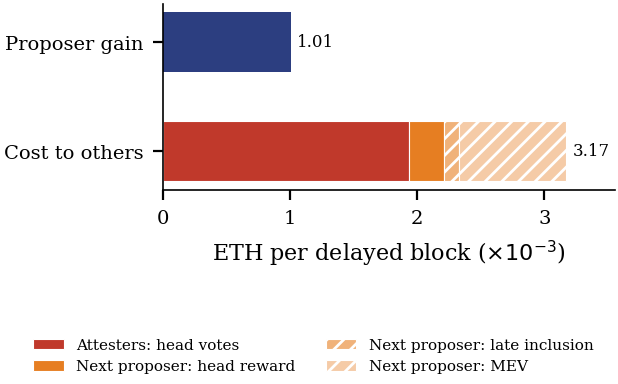

In [45]:
bar_parts = [("Attesters: head votes",         att_loss,      "#C0392B", None),
             ("Next proposer: head reward",    att_loss / 7,  "#E67E22", None),
             ("Next proposer: late inclusion", inc_loss,      "#F0B27A", "////"),
             ("Next proposer: MEV",            next_mev_loss, "#F5CBA7", "////")]

fig, ax = plt.subplots(figsize=(3.33, 2.0))
ax.barh(1, gain * 1e3, color="#2C3E80", height=.55)
ax.text(gain * 1e3 + .05, 1, f"{gain * 1e3:.2f}", va="center", fontsize=6)
left = 0
for lbl, v, c, h in bar_parts:
    ax.barh(0, v * 1e3, left=left, color=c, height=.55, label=lbl,
            hatch=h, edgecolor="white", linewidth=.4)
    left += v * 1e3
ax.text(left + .05, 0, f"{left:.2f}", va="center", fontsize=6)
ax.set_yticks([1, 0], ["Proposer gain", "Cost to others"])
ax.set_xlabel(r"ETH per delayed block ($\times 10^{-3}$)")
ax.set_xlim(0, left * 1.12)
ax.spines[["top", "right"]].set_visible(False)
fig.legend(*ax.get_legend_handles_labels(), fontsize=5.5, frameon=False,
           ncol=2, loc="lower center", bbox_to_anchor=(.5, -.02))
plt.tight_layout(rect=(0, .2, 1, 1))
fig.savefig("fig/gain_vs_cost.pdf", bbox_inches="tight")

In [46]:
def to_json(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating,)):
        return float(v)
    return v


with open("numbers.json", "w") as fh:
    json.dump({k: to_json(v) for k, v in NUM.items()}, fh, indent=2, default=to_json)
print(json.dumps({k: to_json(v) for k, v in NUM.items()}, indent=2, default=to_json))

{
  "obs_total": 541048823,
  "sentries_total": 3225,
  "sentries_kept": 108,
  "obs_kept": 277581831,
  "sentry_median_min": 1717.6313152065911,
  "sentry_median_max": 2769.2447497323024,
  "sentry_median_std": 228.16485664370066,
  "slots_used": 5435149,
  "slots_total": 5479200,
  "share_above_4500ms": 0.003945062039697532,
  "opmonths_dropped_over_4s": 0.0013504388926400823,
  "operators": 108,
  "operator_blocks": 0.8777733842330296,
  "late_share_all": 0.12995577894144358,
  "adopters": 14,
  "exiters": 1,
  "persistent": 7,
  "non_delayers": 86,
  "adopter_delay_increase_ms": 844.0,
  "stake_delaying_eth": 9744080.0,
  "stake_delaying_share": 0.22072542637045092,
  "rel_mev_delaying": 1.0806828047764427,
  "rel_mev_non": 1.0015960795013321,
  "mev_scatter_operators": 83,
  "mev_scatter_rho": 0.4714167270391756,
  "mev_scatter_p": 6.848754275513898e-06,
  "gain_full_median_eth": 0.0011419934719036368,
  "gain_full_total_eth": 830.2381465526485,
  "reorg_operators": 83,
  "reorg_n

## Export the release data

Copies every cache this run read into `data/`, compressed, so that the
notebook can be rerun offline from the repository. Run once, after a full
online run. GitHub rejects files over 100 MB; the cell flags any that are.

In [49]:
EXPORT_RELEASE = False


def export_release(names, out_dir=DATA_DIR, limit_mb=95):
    os.makedirs(out_dir, exist_ok=True)
    rows = []
    for name in dict.fromkeys(names):                 # unique, in order of use
        src = next((os.path.join(d_, f"cache_{name}.parquet") for d_ in (".", out_dir)
                    if os.path.exists(os.path.join(d_, f"cache_{name}.parquet"))), None)
        if src is None:
            rows.append((name, None, "missing"))
            continue
        dst = os.path.join(out_dir, f"cache_{name}.parquet")
        pd.read_parquet(src).to_parquet(dst + ".tmp", compression="zstd", index=False)
        os.replace(dst + ".tmp", dst)
        mb = os.path.getsize(dst) / 2**20
        rows.append((name, round(mb, 1), "TOO LARGE for GitHub" if mb > limit_mb else "ok"))
    report = pd.DataFrame(rows, columns=["cache", "MB", "status"])
    print(report.to_string(index=False))
    print(f"total {report.MB.sum():.0f} MB in {out_dir}/")
    return report


if EXPORT_RELEASE:
    export_release(CACHE_USED)

           cache   MB status
          sentry  0.1     ok
   sentry_median  0.0     ok
             arr 26.9     ok
            prop 33.3     ok
           nodes  8.4     ok
             mev 50.9     ok
      block_meta 52.1     ok
          eb_end  3.0     ok
             bid 16.6     ok
     attestation 23.7     ok
 balance_monthly  0.0     ok
burden_3200_4000  0.4     ok
  late_inclusion 15.6     ok
total 231 MB in data/


## Optional robustness checks (slow; not needed for the paper's numbers)

In [48]:
RUN_OPTIONAL = False

if RUN_OPTIONAL:
    # Attester burden with a 3.5-4 s late window
    alt = cached("burden_3500_4000", lambda: pull(by_attester((3500, 4000))))
    _, alt_grp = attester_burden(alt, att_loss * N)
    print("burden, 3.5-4 s window:")
    print(alt_grp[["vote", "loss", "burden"]].round(2).to_string())

    # Fixed panel: sentries present in every month of the window
    life = sentry.groupby("meta_client_name").agg(months=("ym", "nunique"),
                                                  med_slots=("n_slots", "median"))
    fixed = life[(life.months >= len(MONTHS)) & (life.med_slots >= 1000)].index.tolist()
    fixed_sql = ",".join(f"'{s_}'" for s_ in fixed)
    arr_fix = cached("arr_fixed", lambda: pull(lambda lo, hi: client.query_df(f"""
        SELECT slot, toUInt32(quantile(0.5)(propagation_slot_start_diff)) AS t_ms,
               uniq(meta_client_name) AS n_sentry
        FROM beacon_api_eth_v1_events_block
        WHERE slot_start_date_time >= '{lo}' AND slot_start_date_time < '{hi}'
          AND propagation_slot_start_diff < {MAX_MS}
          AND meta_client_name IN ({fixed_sql})
        GROUP BY slot
    """, settings=CH)))
    arr_fix = in_window(arr_fix[arr_fix.n_sentry >= max(5, len(fixed) // 2)].copy())
    arr_fix["ym"] = slot_time(arr_fix.slot).dt.to_period("M").values
    print(f"fixed panel: {len(fixed)} sentries")
    print(arr_fix.groupby("ym").t_ms.median().to_frame("fixed_med")
                 .join(arr.groupby("ym").t_ms.median().rename("main_med")).to_string())